#### Part 1

In [153]:
import gurobipy as gp
from gurobipy import GRB

# Sets
jobs = [1, 2, 3, 4]
ops = {1: [1, 2, 3, 4], 2: [1, 2, 3, 4], 3: [1, 2, 3, 4], 4: [1, 2, 3]} 
machines = [1, 2, 3, 4]

# Processing times p[j,k,m]
p = {
    (1,1,1):8, (1,1,2):1, (1,1,3):4, (1,1,4):5,
    (1,2,1):2, (1,2,2):1, (1,2,3):10, (1,2,4):4,
    (1,3,1):4, (1,3,2):2, (1,3,3):8, (1,3,4):2,
    (1,4,1):5, (1,4,2):7, (1,4,3):8, (1,4,4):8,

    (2,1,1):3, (2,1,2):2, (2,1,3):5, (2,1,4):7,
    (2,2,1):5, (2,2,2):10, (2,2,3):10, (2,2,4):8,
    (2,3,1):9, (2,3,2):7, (2,3,3):8, (2,3,4):6,
    (2,4,1):7, (2,4,2):1, (2,4,3):6, (2,4,4):8,

    (3,1,1):3, (3,1,2):8, (3,1,3):1, (3,1,4):3,
    (3,2,1):8, (3,2,2):2, (3,2,3):9, (3,2,4):8,
    (3,3,1):2, (3,3,2):8, (3,3,3):5, (3,3,4):6,
    (3,4,1):9, (3,4,2):7, (3,4,3):6, (3,4,4):8,

    # Job 4: Only 3 operations
    (4,1,1):4, (4,1,2):2, (4,1,3):7, (4,1,4):2,
    (4,2,1):5, (4,2,2):1, (4,2,3):1, (4,2,4):6,
    (4,3,1):9, (4,3,2):7, (4,3,3):10, (4,3,4):3
}

# Create the optimization model
model = gp.Model("JobShop")

# Assignment variable
x = model.addVars(jobs, [k for k in ops[1]], machines, vtype=GRB.BINARY, name="x")  # Add only up to 4 operations for Job 1-3
S = model.addVars(jobs, [k for k in ops[1]], lb=0, name="S")
C = model.addVars(jobs, [k for k in ops[1]], lb=0, name="C")

# Makespan
Cmax = model.addVar(lb=0, name="Cmax")

model.setObjective(Cmax, GRB.MINIMIZE)

# PART I
# Constraints
for j in jobs:
    for k in ops[j]:  # Loop only over valid operations for each job
        model.addConstr(gp.quicksum(x[j, k, m] for m in machines) == 1)

for j in jobs:
    for k in ops[j]:  # Loop only over valid operations for each job
        model.addConstr(C[j, k] == S[j, k] + gp.quicksum(p[j, k, m] * x[j, k, m] for m in machines))

for j in jobs:
    for k in ops[j][:-1]:  # Only enforce precedence for valid operations
        model.addConstr(S[j, k+1] >= C[j, k]) 

for j in jobs:
    for k in ops[j]:
        model.addConstr(Cmax >= C[j, k]) 

# Optimize the model
model.optimize()

# Output the results
if model.status == GRB.OPTIMAL:
    print(f"Optimal Makespan: {Cmax.X}")
    for j in jobs:
        for k in ops[j]:
            # Find which machine is assigned to the operation
            for m in machines:
                if x[j, k, m].X > 0.5:  # x[j, k, m] = 1 means machine m is assigned
                    print(f"Job {j}, Operation {k}: Start time = {S[j, k].X}, Completion time = {C[j, k].X}, Assigned to Machine {m}")
else:
    print("No optimal solution found")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 56 rows, 97 columns and 202 nonzeros
Model fingerprint: 0x1980143a
Variable types: 33 continuous, 64 integer (64 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 16.0000000
Presolve removed 56 rows and 97 columns
Presolve time: 0.03s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.09 seconds (0.00 work units)
Thread count was 1 (of 4 available processors)

Solution count 2: 14 16 

Optimal solution found (tolerance 1.00e-04)
Best objective 1.400000000000e+01, best bound 1.400000000000e+01, gap 0.0000%
Optimal Makespan: 14.0
Job 1, Operation 1: Start time = 0.0, C

In [154]:
import gurobipy as gp
from gurobipy import GRB

# Sets
jobs = [1, 2, 3, 4]
ops = {1: [1, 2, 3, 4], 2: [1, 2, 3, 4], 3: [1, 2, 3, 4], 4: [1, 2, 3]} 
machines = [1, 2, 3, 4]

# Processing times p[j,k,m]
p = {
    (1,1,1):8, (1,1,2):1, (1,1,3):4, (1,1,4):5,
    (1,2,1):2, (1,2,2):1, (1,2,3):10, (1,2,4):4,
    (1,3,1):4, (1,3,2):2, (1,3,3):8, (1,3,4):2,
    (1,4,1):5, (1,4,2):7, (1,4,3):8, (1,4,4):8,

    (2,1,1):3, (2,1,2):2, (2,1,3):5, (2,1,4):7,
    (2,2,1):5, (2,2,2):10, (2,2,3):10, (2,2,4):8,
    (2,3,1):9, (2,3,2):7, (2,3,3):8, (2,3,4):6,
    (2,4,1):7, (2,4,2):1, (2,4,3):6, (2,4,4):8,

    (3,1,1):3, (3,1,2):8, (3,1,3):1, (3,1,4):3,
    (3,2,1):8, (3,2,2):2, (3,2,3):9, (3,2,4):8,
    (3,3,1):2, (3,3,2):8, (3,3,3):5, (3,3,4):6,
    (3,4,1):9, (3,4,2):7, (3,4,3):6, (3,4,4):8,

    # Job 4: Only 3 operations
    (4,1,1):4, (4,1,2):2, (4,1,3):7, (4,1,4):2,
    (4,2,1):5, (4,2,2):1, (4,2,3):1, (4,2,4):6,
    (4,3,1):9, (4,3,2):7, (4,3,3):10, (4,3,4):3
}

# Create the optimization model
model = gp.Model("JobShop")

# Assignment variable
x = model.addVars(jobs, [k for k in ops[1]], machines, vtype=GRB.BINARY, name="x")  # Add only up to 4 operations for Job 1-3
S = model.addVars(jobs, [k for k in ops[1]], lb=0, name="S")
C = model.addVars(jobs, [k for k in ops[1]], lb=0, name="C")

# Makespan
Cmax = model.addVar(lb=0, name="Cmax")

model.setObjective(Cmax, GRB.MINIMIZE)

# PART I
# Constraints
for j in jobs:
    for k in ops[j]:  # Loop only over valid operations for each job
        model.addConstr(gp.quicksum(x[j, k, m] for m in machines) == 1)

for j in jobs:
    for k in ops[j]:  # Loop only over valid operations for each job
        model.addConstr(C[j, k] == S[j, k] + gp.quicksum(p[j, k, m] * x[j, k, m] for m in machines))

for j in jobs:
    for k in ops[j][:-1]:  # Only enforce precedence for valid operations
        model.addConstr(S[j, k+1] >= C[j, k]) 

for j in jobs:
    for k in ops[j]:
        model.addConstr(Cmax >= C[j, k]) 

# Optimize the model
model.optimize()

# Output the results
if model.status == GRB.OPTIMAL:
    print(f"Optimal Makespan: {Cmax.X}")
    for j in jobs:
        for k in ops[j]:
            # Find which machine is assigned to the operation
            for m in machines:
                if x[j, k, m].X > 0.5:  # x[j, k, m] = 1 means machine m is assigned
                    print(f"Job {j}, Operation {k}: Start time = {S[j, k].X}, Completion time = {C[j, k].X}, Assigned to Machine {m}")
else:
    print("No optimal solution found")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 56 rows, 97 columns and 202 nonzeros
Model fingerprint: 0x1980143a
Variable types: 33 continuous, 64 integer (64 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 16.0000000
Presolve removed 56 rows and 97 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.03 seconds (0.00 work units)
Thread count was 1 (of 4 available processors)

Solution count 2: 14 16 

Optimal solution found (tolerance 1.00e-04)
Best objective 1.400000000000e+01, best bound 1.400000000000e+01, gap 0.0000%
Optimal Makespan: 14.0
Job 1, Operation 1: Start time = 0.0, C

#### All code test

In [13]:
import gurobipy as gp
from gurobipy import GRB

# =========================================================
# 1. DATA
# =========================================================

jobs = [1, 2, 3, 4]
machines = [1, 2, 3, 4]

operations = {
    1: [1,2,3,4],
    2: [1,2,3,4],
    3: [1,2,3,4],
    4: [1,2,3]
}

# Processing times p[j,k,m]
p = {
 (1,1,1):8,(1,1,2):1,(1,1,3):4,(1,1,4):5,
 (1,2,1):2,(1,2,2):1,(1,2,3):10,(1,2,4):4,
 (1,3,1):4,(1,3,2):2,(1,3,3):8,(1,3,4):2,
 (1,4,1):5,(1,4,2):7,(1,4,3):8,(1,4,4):8,

 (2,1,1):3,(2,1,2):2,(2,1,3):5,(2,1,4):7,
 (2,2,1):5,(2,2,2):10,(2,2,3):10,(2,2,4):8,
 (2,3,1):9,(2,3,2):7,(2,3,3):8,(2,3,4):6,
 (2,4,1):7,(2,4,2):1,(2,4,3):6,(2,4,4):8,

 (3,1,1):3,(3,1,2):8,(3,1,3):1,(3,1,4):3,
 (3,2,1):8,(3,2,2):2,(3,2,3):9,(3,2,4):8,
 (3,3,1):2,(3,3,2):8,(3,3,3):5,(3,3,4):6,
 (3,4,1):9,(3,4,2):7,(3,4,3):6,(3,4,4):8,

 (4,1,1):4,(4,1,2):2,(4,1,3):7,(4,1,4):2,
 (4,2,1):5,(4,2,2):1,(4,2,3):1,(4,2,4):6,
 (4,3,1):9,(4,3,2):7,(4,3,3):10,(4,3,4):3
}

# Emission costs e[j,k,m]
e = {
 (1,1,1):3.20,(1,1,2):4.71,(1,1,3):2.75,(1,1,4):3.79,
 (1,2,1):3.84,(1,2,2):2.24,(1,2,3):1.05,(1,2,4):2.63,
 (1,3,1):3.59,(1,3,2):1.62,(1,3,3):4.73,(1,3,4):2.17,
 (1,4,1):1.97,(1,4,2):3.21,(1,4,3):2.53,(1,4,4):4.69,

 (2,1,1):2.36,(2,1,2):4.15,(2,1,3):2.07,(2,1,4):1.01,
 (2,2,1):4.46,(2,2,2):2.79,(2,2,3):2.94,(2,2,4):2.33,
 (2,3,1):4.48,(2,3,2):4.92,(2,3,3):1.96,(2,3,4):2.53,
 (2,4,1):3.82,(2,4,2):4.25,(2,4,3):2.54,(2,4,4):3.65,

 (3,1,1):3.01,(3,1,2):3.36,(3,1,3):4.48,(3,1,4):4.50,
 (3,2,1):1.06,(3,2,2):1.58,(3,2,3):4.48,(3,2,4):4.88,
 (3,3,1):3.49,(3,3,2):2.59,(3,3,3):1.32,(3,3,4):2.31,
 (3,4,1):4.49,(3,4,2):1.14,(3,4,3):1.27,(3,4,4):3.52,

 (4,1,1):4.04,(4,1,2):3.82,(4,1,3):1.40,(4,1,4):1.67,
 (4,2,1):4.18,(4,2,2):2.17,(4,2,3):2.50,(4,2,4):1.58,
 (4,3,1):1.68,(4,3,2):1.32,(4,3,3):4.48,(4,3,4):3.48
}

# =========================================================
# 2. MODEL
# =========================================================

model = gp.Model("Job_Shop_Problem")

# =========================================================
# 3. VARIABLES
# =========================================================

x = model.addVars(
    [(j,k,m) for j in jobs for k in operations[j] for m in machines],
    vtype=GRB.BINARY,
    name="x"
)

S = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="S"
)

C = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="C"
)

Cmax = model.addVar(lb=0, name="Cmax")

# Sequencing variables
y = model.addVars(
    [(j,k,jp,kp,m)
     for j in jobs for k in operations[j]
     for jp in jobs for kp in operations[jp]
     if (j,k) < (jp,kp)
     for m in machines],
    vtype=GRB.BINARY,
    name="y"
)

# =========================================================
# 4. OBJECTIVE (Makespan)
# =========================================================

model.setObjective(Cmax, GRB.MINIMIZE)

# =========================================================
# 5. CONSTRAINTS
# =========================================================

# (i) Assignment
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            gp.quicksum(x[j,k,m] for m in machines) == 1
        )

# Completion time
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            C[j,k] == S[j,k] +
            gp.quicksum(p[j,k,m]*x[j,k,m] for m in machines)
        )

# Precedence
for j in jobs:
    for idx in range(len(operations[j]) - 1):
        k = operations[j][idx]
        k_next = operations[j][idx + 1]
        model.addConstr(S[j,k_next] >= C[j,k])

# Makespan
for j in jobs:
    for k in operations[j]:
        model.addConstr(Cmax >= C[j,k])

# (ii) Machine capacity
M = 1000
for (j,k,jp,kp,m) in y.keys():
    model.addConstr(
        S[j,k] >= C[jp,kp]
        - M*(1 - y[j,k,jp,kp,m])
        - M*(2 - x[j,k,m] - x[jp,kp,m])
    )
    model.addConstr(
        S[jp,kp] >= C[j,k]
        - M*y[j,k,jp,kp,m]
        - M*(2 - x[j,k,m] - x[jp,kp,m])
    )

# (iii) Machine workload bound
alpha = 40
for m in machines:
    model.addConstr(
        gp.quicksum(p[j,k,m]*x[j,k,m]
                    for j in jobs for k in operations[j]) <= alpha
    )

# =========================================================
# (v) Emission Objective (ε-constraint example)
# =========================================================

Emission = gp.quicksum(
    e[j,k,m]*x[j,k,m]
    for j in jobs for k in operations[j] for m in machines
)

model.addConstr(Emission <= 60)

# =========================================================
# 6. SOLVE
# =========================================================

model.optimize()

# =========================================================
# 7. OUTPUT
# =========================================================

print("\nOptimal Makespan:", Cmax.X)
print("Total Emissions:", Emission.getValue())

for j in jobs:
    for k in operations[j]:
        for m in machines:
            if x[j,k,m].X > 0.5:
                print(f"Job {j}, Op {k} -> Machine {m}, "
                      f"Start {S[j,k].X:.2f}, "
                      f"Finish {C[j,k].X:.2f}")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 901 rows, 511 columns and 4522 nonzeros
Model fingerprint: 0x6f748f6d
Variable types: 31 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Presolve removed 44 rows and 44 columns
Presolve time: 0.01s
Presolved: 857 rows, 467 columns, 4225 nonzeros
Variable types: 31 continuous, 436 integer (436 binary)
Found heuristic solution: objective 58.0000000
Found heuristic solution: objective 38.0000000

Root relaxation: objective 1.400000e+01, 71 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestB

In [14]:
def print_solution(title, model, x, S, C, Cmax, jobs, operations, machines):
    print("\n" + "="*70)
    print(title)
    print("="*70)

    if model.Status != GRB.OPTIMAL:
        print("No optimal solution found.")
        return

    print(f"Optimal Makespan (Cmax): {Cmax.X:.2f}\n")

    print("Schedule:")
    for j in jobs:
        for k in operations[j]:
            for m in machines:
                if x[j,k,m].X > 0.5:
                    print(f"  Job {j}, Operation {k} "
                          f"-> Machine {m}, "
                          f"Start = {S[j,k].X:.2f}, "
                          f"Finish = {C[j,k].X:.2f}")


In [15]:
print_solution(
    title="Question 1(i): Basic Job Shop Problem (No Machine Capacity Constraints)",
    model=model,
    x=x, S=S, C=C, Cmax=Cmax,
    jobs=jobs, operations=operations, machines=machines
)



Question 1(i): Basic Job Shop Problem (No Machine Capacity Constraints)
Optimal Makespan (Cmax): 15.00

Schedule:
  Job 1, Operation 1 -> Machine 2, Start = 0.00, Finish = 1.00
  Job 1, Operation 2 -> Machine 4, Start = 1.00, Finish = 5.00
  Job 1, Operation 3 -> Machine 4, Start = 5.00, Finish = 7.00
  Job 1, Operation 4 -> Machine 1, Start = 8.00, Finish = 13.00
  Job 2, Operation 1 -> Machine 1, Start = 0.00, Finish = 3.00
  Job 2, Operation 2 -> Machine 1, Start = 3.00, Finish = 8.00
  Job 2, Operation 3 -> Machine 4, Start = 8.00, Finish = 14.00
  Job 2, Operation 4 -> Machine 2, Start = 14.00, Finish = 15.00
  Job 3, Operation 1 -> Machine 3, Start = 0.00, Finish = 1.00
  Job 3, Operation 2 -> Machine 2, Start = 1.00, Finish = 3.00
  Job 3, Operation 3 -> Machine 3, Start = 3.00, Finish = 8.00
  Job 3, Operation 4 -> Machine 3, Start = 8.00, Finish = 14.00
  Job 4, Operation 1 -> Machine 2, Start = 3.00, Finish = 5.00
  Job 4, Operation 2 -> Machine 2, Start = 5.00, Finish = 6.0

In [16]:
print("\nMachine-wise Operation Sequences (Question 1(ii))")

for m in machines:
    print(f"\nMachine {m}:")
    ops_on_m = []
    for j in jobs:
        for k in operations[j]:
            if x[j,k,m].X > 0.5:
                ops_on_m.append((S[j,k].X, j, k))
    ops_on_m.sort()

    for s, j, k in ops_on_m:
        print(f"  Job {j}, Op {k}, Start {s:.2f}, Finish {C[j,k].X:.2f}")



Machine-wise Operation Sequences (Question 1(ii))

Machine 1:
  Job 2, Op 1, Start 0.00, Finish 3.00
  Job 2, Op 2, Start 3.00, Finish 8.00
  Job 1, Op 4, Start 8.00, Finish 13.00

Machine 2:
  Job 1, Op 1, Start 0.00, Finish 1.00
  Job 3, Op 2, Start 1.00, Finish 3.00
  Job 4, Op 1, Start 3.00, Finish 5.00
  Job 4, Op 2, Start 5.00, Finish 6.00
  Job 4, Op 3, Start 6.00, Finish 13.00
  Job 2, Op 4, Start 14.00, Finish 15.00

Machine 3:
  Job 3, Op 1, Start 0.00, Finish 1.00
  Job 3, Op 3, Start 3.00, Finish 8.00
  Job 3, Op 4, Start 8.00, Finish 14.00

Machine 4:
  Job 1, Op 2, Start 1.00, Finish 5.00
  Job 1, Op 3, Start 5.00, Finish 7.00
  Job 2, Op 3, Start 8.00, Finish 14.00


In [17]:
print("\nQuestion 1(iii): Machine Workload")

for m in machines:
    workload = sum(
        p[j,k,m]*x[j,k,m].X
        for j in jobs for k in operations[j]
    )
    print(f"Machine {m}: Total Workload = {workload:.2f}")



Question 1(iii): Machine Workload
Machine 1: Total Workload = 13.00
Machine 2: Total Workload = 14.00
Machine 3: Total Workload = 12.00
Machine 4: Total Workload = 12.00


In [18]:
print("\nQuestion 1(iv): Sensitivity Analysis on α")
print(f"α = {alpha:.2f}")
print(f"Resulting Makespan = {Cmax.X:.2f}")

for m in machines:
    workload = sum(
        p[j,k,m]*x[j,k,m].X
        for j in jobs for k in operations[j]
    )
    print(f"  Machine {m}: Workload = {workload:.2f}")



Question 1(iv): Sensitivity Analysis on α
α = 40.00
Resulting Makespan = 15.00
  Machine 1: Workload = 13.00
  Machine 2: Workload = 14.00
  Machine 3: Workload = 12.00
  Machine 4: Workload = 12.00


In [19]:
print("\nQuestion 1(v): Emissions and Makespan Trade-off")

total_emission = sum(
    e[j,k,m]*x[j,k,m].X
    for j in jobs for k in operations[j] for m in machines
)

print(f"Total Emission Cost = {total_emission:.2f}")
print(f"Makespan = {Cmax.X:.2f}")



Question 1(v): Emissions and Makespan Trade-off
Total Emission Cost = 41.04
Makespan = 15.00


#### Part 2

In [155]:
import gurobipy as gp
from gurobipy import GRB

# =========================================================
# 1. DATA
# =========================================================

jobs = [1, 2, 3, 4]
machines = [1, 2, 3, 4]

operations = {
    1: [1, 2, 3, 4],
    2: [1, 2, 3, 4],
    3: [1, 2, 3, 4],
    4: [1, 2, 3]
}

# Processing times p[j,k,m]
p = {
    (1,1,1):8,(1,1,2):1,(1,1,3):4,(1,1,4):5,
    (1,2,1):2,(1,2,2):1,(1,2,3):10,(1,2,4):4,
    (1,3,1):4,(1,3,2):2,(1,3,3):8,(1,3,4):2,
    (1,4,1):5,(1,4,2):7,(1,4,3):8,(1,4,4):8,

    (2,1,1):3,(2,1,2):2,(2,1,3):5,(2,1,4):7,
    (2,2,1):5,(2,2,2):10,(2,2,3):10,(2,2,4):8,
    (2,3,1):9,(2,3,2):7,(2,3,3):8,(2,3,4):6,
    (2,4,1):7,(2,4,2):1,(2,4,3):6,(2,4,4):8,

    (3,1,1):3,(3,1,2):8,(3,1,3):1,(3,1,4):3,
    (3,2,1):8,(3,2,2):2,(3,2,3):9,(3,2,4):8,
    (3,3,1):2,(3,3,2):8,(3,3,3):5,(3,3,4):6,
    (3,4,1):9,(3,4,2):7,(3,4,3):6,(3,4,4):8,

    (4,1,1):4,(4,1,2):2,(4,1,3):7,(4,1,4):2,
    (4,2,1):5,(4,2,2):1,(4,2,3):1,(4,2,4):6,
    (4,3,1):9,(4,3,2):7,(4,3,3):10,(4,3,4):3
}

# =========================================================
# 2. MODEL
# =========================================================

model = gp.Model("Job_Shop_Problem")

# =========================================================
# 3. VARIABLES
# =========================================================

x = model.addVars(
    [(j,k,m) for j in jobs for k in operations[j] for m in machines],
    vtype=GRB.BINARY,
    name="x"
)

S = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="S"
)

C = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="C"
)

Cmax = model.addVar(lb=0, name="Cmax")

# Sequencing variables
y = model.addVars(
    [(j,k,jp,kp,m)
     for j in jobs for k in operations[j]
     for jp in jobs for kp in operations[jp]
     if (j,k) < (jp,kp)
     for m in machines],
    vtype=GRB.BINARY,
    name="y"
)

# =========================================================
# 4. OBJECTIVE (Makespan)
# =========================================================

model.setObjective(Cmax, GRB.MINIMIZE)  # Minimize makespan

# =========================================================
# 5. CONSTRAINTS
# =========================================================

# (i) Assignment - Each job-operation must be assigned to exactly one machine
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            gp.quicksum(x[j,k,m] for m in machines) == 1
        )

# Completion time - Define the completion time for each job-operation on each machine
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
        )

# Precedence - Ensure that the operations within each job follow the correct order
for j in jobs:
    for idx in range(len(operations[j]) - 1):
        k = operations[j][idx]
        k_next = operations[j][idx + 1]
        model.addConstr(S[j,k_next] >= C[j,k])

# Makespan - The completion time of the last operation should define the makespan
for j in jobs:
    for k in operations[j]:
        model.addConstr(Cmax >= C[j,k])

# Sequencing constraints - Ensure that jobs don't overlap on the same machine
M = 1000  # Big-M value
for (j,k,jp,kp,m) in y.keys():
    model.addConstr(
        S[j,k] >= C[jp,kp]
        - M * (1 - y[j,k,jp,kp,m])
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )
    model.addConstr(
        S[jp,kp] >= C[j,k]
        - M * y[j,k,jp,kp,m]
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )

# =========================================================
# 6. SOLVE
# =========================================================

model.optimize()

# =========================================================
# 7. OUTPUT
# =========================================================

print("\nOptimal Makespan:", Cmax.X)

for j in jobs:
    for k in operations[j]:
        for m in machines:
            if x[j,k,m].X > 0.5:
                print(f"Job {j}, Op {k} -> Machine {m}, "
                      f"Start {S[j,k].X:.2f}, "
                      f"Finish {C[j,k].X:.2f}")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 896 rows, 511 columns and 4402 nonzeros
Model fingerprint: 0xeb1e4252
Variable types: 31 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Presolve removed 44 rows and 44 columns
Presolve time: 0.02s
Presolved: 852 rows, 467 columns, 4120 nonzeros
Variable types: 31 continuous, 436 integer (436 binary)
Found heuristic solution: objective 35.0000000

Root relaxation: objective 1.400000e+01, 35 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0   14.00000

#### Part 4


In [51]:
import gurobipy as gp
from gurobipy import GRB

# =========================================================
# 1. DATA (same as before)
# =========================================================

jobs = [1, 2, 3, 4]
machines = [1, 2, 3, 4]

operations = {
    1: [1, 2, 3, 4],
    2: [1, 2, 3, 4],
    3: [1, 2, 3, 4],
    4: [1, 2, 3]
}

# Processing times p[j,k,m]
p = {
    (1,1,1):8,(1,1,2):1,(1,1,3):4,(1,1,4):5,
    (1,2,1):2,(1,2,2):1,(1,2,3):10,(1,2,4):4,
    (1,3,1):4,(1,3,2):2,(1,3,3):8,(1,3,4):2,
    (1,4,1):5,(1,4,2):7,(1,4,3):8,(1,4,4):8,

    (2,1,1):3,(2,1,2):2,(2,1,3):5,(2,1,4):7,
    (2,2,1):5,(2,2,2):10,(2,2,3):10,(2,2,4):8,
    (2,3,1):9,(2,3,2):7,(2,3,3):8,(2,3,4):6,
    (2,4,1):7,(2,4,2):1,(2,4,3):6,(2,4,4):8,

    (3,1,1):3,(3,1,2):8,(3,1,3):1,(3,1,4):3,
    (3,2,1):8,(3,2,2):2,(3,2,3):9,(3,2,4):8,
    (3,3,1):2,(3,3,2):8,(3,3,3):5,(3,3,4):6,
    (3,4,1):9,(3,4,2):7,(3,4,3):6,(3,4,4):8,

    (4,1,1):4,(4,1,2):2,(4,1,3):7,(4,1,4):2,
    (4,2,1):5,(4,2,2):1,(4,2,3):1,(4,2,4):6,
    (4,3,1):9,(4,3,2):7,(4,3,3):10,(4,3,4):3
}

# =========================================================
# 2. MODEL
# =========================================================

# Function to create and solve the model for a given alpha value
def solve_model_for_alpha(alpha):
    # Create model
    model = gp.Model("Job_Shop_Problem")
    
    # Variables
    x = model.addVars(
        [(j, k, m) for j in jobs for k in operations[j] for m in machines],
        vtype=GRB.BINARY,
        name="x"
    )

    S = model.addVars(
        [(j, k) for j in jobs for k in operations[j]],
        lb=0,
        name="S"
    )

    C = model.addVars(
        [(j, k) for j in jobs for k in operations[j]],
        lb=0,
        name="C"
    )

    Cmax = model.addVar(lb=0, name="Cmax")

    # Sequencing variables
    y = model.addVars(
        [(j, k, jp, kp, m)
         for j in jobs for k in operations[j]
         for jp in jobs for kp in operations[jp]
         if (j, k) < (jp, kp)
         for m in machines],
        vtype=GRB.BINARY,
        name="y"
    )

    # Objective: Minimize makespan
    model.setObjective(Cmax, GRB.MINIMIZE)

    # Constraints (same as before)
    # (i) Assignment constraint
    for j in jobs:
        for k in operations[j]:
            model.addConstr(gp.quicksum(x[j, k, m] for m in machines) == 1)

    # (ii) Completion time constraint
    for j in jobs:
        for k in operations[j]:
            model.addConstr(
                C[j, k] == S[j, k] + gp.quicksum(p[j, k, m] * x[j, k, m] for m in machines)
            )

    # (iii) Precedence constraints
    for j in jobs:
        for idx in range(len(operations[j]) - 1):
            k = operations[j][idx]
            k_next = operations[j][idx + 1]
            model.addConstr(S[j, k_next] >= C[j, k])

    # (iv) Makespan constraint
    for j in jobs:
        for k in operations[j]:
            model.addConstr(Cmax >= C[j, k])

    # (v) Machine workload constraint
    for m in machines:
        model.addConstr(
            gp.quicksum(p[j, k, m] * x[j, k, m] for j in jobs for k in operations[j]) <= alpha
        )

    # Solve the model
    model.optimize()

    # Output results if the model is solved successfully
    if model.status == GRB.OPTIMAL:
        print(f"\nOptimal Makespan for alpha = {alpha}: {Cmax.X}")
        for j in jobs:
            for k in operations[j]:
                for m in machines:
                    if x[j, k, m].X > 0.5:
                        print(f"Job {j}, Op {k} -> Machine {m}, "
                              f"Start {S[j, k].X:.2f}, Finish {C[j, k].X:.2f}")
        return Cmax.X
    else:
        print(f"Model is infeasible for alpha = {alpha}")
        return None

# =========================================================
# 3. SENSITIVITY ANALYSIS FOR ALPHA
# =========================================================

alpha_values = [11,12,20,30,40,50,100,200,300]  # Different values of alpha to check

for alpha in alpha_values:
    solve_model_for_alpha(alpha)


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 60 rows, 511 columns and 262 nonzeros
Model fingerprint: 0xe635581c
Variable types: 31 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+01]


Presolve removed 31 rows and 444 columns
Presolve time: 0.04s
Presolved: 29 rows, 67 columns, 184 nonzeros
Variable types: 7 continuous, 60 integer (60 binary)

Root relaxation: objective 1.400000e+01, 19 iterations, 0.03 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0   14.00000    0    5          -   14.00000      -     -    0s
     0     0 infeasible    0               - infeasible      -     -    0s

Cutting planes:
  Gomory: 2
  Cover: 5
  MIR: 2
  StrongCG: 1
  RLT: 2
  Relax-and-lift: 1

Explored 1 nodes (27 simplex iterations) in 0.18 seconds (0.00 work units)
Thread count was 4 (of 4 available processors)

Solution count 0

Model is infeasible
Best objective -, best bound -, gap -
Model is infeasible for alpha = 11
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000N

In [21]:
import pandas as pd

# List of different values of alpha (workload limits)
alpha_values = [30, 50, 70, 90, 110]

# Prepare to store results for each alpha value
results = []

# Loop through different alpha values and solve the model
for alpha in alpha_values:
    # Create a new model for each alpha
    model = gp.Model("Job_Shop_Problem")

    # Add variables
    x = model.addVars(
        [(j,k,m) for j in jobs for k in operations[j] for m in machines],
        vtype=GRB.BINARY,
        name="x"
    )

    S = model.addVars(
        [(j,k) for j in jobs for k in operations[j]],
        lb=0,
        name="S"
    )

    C = model.addVars(
        [(j,k) for j in jobs for k in operations[j]],
        lb=0,
        name="C"
    )

    Cmax = model.addVar(lb=0, name="Cmax")

    # Sequencing variables
    y = model.addVars(
        [(j,k,jp,kp,m)
         for j in jobs for k in operations[j]
         for jp in jobs for kp in operations[jp]
         if (j,k) < (jp,kp)
         for m in machines],
        vtype=GRB.BINARY,
        name="y"
    )

    # Set the objective (minimize makespan)
    model.setObjective(Cmax, GRB.MINIMIZE)

    # Constraints
    for j in jobs:
        for k in operations[j]:
            model.addConstr(
                gp.quicksum(x[j,k,m] for m in machines) == 1
            )

    for j in jobs:
        for k in operations[j]:
            model.addConstr(
                C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
            )

    for j in jobs:
        for idx in range(len(operations[j]) - 1):
            k = operations[j][idx]
            k_next = operations[j][idx + 1]
            model.addConstr(S[j,k_next] >= C[j,k])

    for j in jobs:
        for k in operations[j]:
            model.addConstr(Cmax >= C[j,k])

    # Sequencing constraints
    M = 1000  # Big-M value
    for (j,k,jp,kp,m) in y.keys():
        model.addConstr(
            S[j,k] >= C[jp,kp]
            - M * (1 - y[j,k,jp,kp,m])
            - M * (2 - x[j,k,m] - x[jp,kp,m])
        )
        model.addConstr(
            S[jp,kp] >= C[j,k]
            - M * y[j,k,jp,kp,m]
            - M * (2 - x[j,k,m] - x[jp,kp,m])
        )

    # Add the workload constraint for each machine m
    for m in machines:
        model.addConstr(
            gp.quicksum(p[j,k,m] * x[j,k,m] for j in jobs for k in operations[j]) <= alpha,
            name=f"Workload_Constraint_m{m}"
        )

    # Solve the model
    model.optimize()

    # Record the makespan
    makespan = Cmax.X

    # Record the workload distribution for each machine
    machine_workloads = {m: sum(p[j,k,m] * x[j,k,m].X for j in jobs for k in operations[j]) for m in machines}

    # Append results for this alpha value
    results.append([alpha, makespan] + [machine_workloads[m] for m in machines])

# Convert results to a DataFrame for better display
df = pd.DataFrame(results, columns=['Alpha', 'Makespan'] + [f'Machine {m} Workload' for m in machines])

# Display the table
print(df)


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 900 rows, 511 columns and 4462 nonzeros
Model fingerprint: 0x41f77d3d
Variable types: 31 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Presolve removed 44 rows and 44 columns
Presolve time: 0.02s
Presolved: 856 rows, 467 columns, 4180 nonzeros
Variable types: 31 continuous, 436 integer (436 binary)
Found heuristic solution: objective 35.0000000
Found heuristic solution: objective 34.0000000
Found heuristic solution: objective 32.0000000

Root relaxation: objective 1.400000e+01, 35 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl U

In [24]:
import pandas as pd

# List of different values of alpha (workload limits)
alpha_values = [10, 11, 12, 13, 14, 15, 20, 30, 50, 70, 90, 110]

# Prepare to store results for each alpha value
results = []
infeasible_alphas = []

# Loop through different alpha values and solve the model
for alpha in alpha_values:
    # Create a new model for each alpha
    model = gp.Model("Job_Shop_Problem")

    # Add variables
    x = model.addVars(
        [(j,k,m) for j in jobs for k in operations[j] for m in machines],
        vtype=GRB.BINARY,
        name="x"
    )

    S = model.addVars(
        [(j,k) for j in jobs for k in operations[j]],
        lb=0,
        name="S"
    )

    C = model.addVars(
        [(j,k) for j in jobs for k in operations[j]],
        lb=0,
        name="C"
    )

    Cmax = model.addVar(lb=0, name="Cmax")

    # Sequencing variables
    y = model.addVars(
        [(j,k,jp,kp,m)
         for j in jobs for k in operations[j]
         for jp in jobs for kp in operations[jp]
         if (j,k) < (jp,kp)
         for m in machines],
        vtype=GRB.BINARY,
        name="y"
    )

    # Set the objective (minimize makespan)
    model.setObjective(Cmax, GRB.MINIMIZE)

    # Constraints
    for j in jobs:
        for k in operations[j]:
            model.addConstr(
                gp.quicksum(x[j,k,m] for m in machines) == 1
            )

    for j in jobs:
        for k in operations[j]:
            model.addConstr(
                C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
            )

    for j in jobs:
        for idx in range(len(operations[j]) - 1):
            k = operations[j][idx]
            k_next = operations[j][idx + 1]
            model.addConstr(S[j,k_next] >= C[j,k])

    for j in jobs:
        for k in operations[j]:
            model.addConstr(Cmax >= C[j,k])

    # Sequencing constraints
    M = 1000  # Big-M value
    for (j,k,jp,kp,m) in y.keys():
        model.addConstr(
            S[j,k] >= C[jp,kp]
            - M * (1 - y[j,k,jp,kp,m])
            - M * (2 - x[j,k,m] - x[jp,kp,m])
        )
        model.addConstr(
            S[jp,kp] >= C[j,k]
            - M * y[j,k,jp,kp,m]
            - M * (2 - x[j,k,m] - x[jp,kp,m])
        )

    # Add the workload constraint for each machine m
    for m in machines:
        model.addConstr(
            gp.quicksum(p[j,k,m] * x[j,k,m] for j in jobs for k in operations[j]) <= alpha,
            name=f"Workload_Constraint_m{m}"
        )

    # Solve the model
    model.optimize()

    # Check if the model is feasible
    if model.status == GRB.INFEASIBLE:
        infeasible_alphas.append(alpha)
    else:
        # If feasible, record the makespan and workload distribution
        makespan = Cmax.X
        machine_workloads = {m: sum(p[j,k,m] * x[j,k,m].X for j in jobs for k in operations[j]) for m in machines}
        results.append([alpha, makespan] + [machine_workloads[m] for m in machines])

# Convert results to a DataFrame for feasible solutions
df = pd.DataFrame(results, columns=['Alpha', 'Makespan'] + [f'Machine {m} Workload' for m in machines])

# Display the feasible solutions table
print("Feasible Solutions:")
print(df)

# Print the infeasible alpha values
print("\nInfeasible Alpha Values:")
if infeasible_alphas:
    print(infeasible_alphas)
else:
    print("None")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 900 rows, 511 columns and 4462 nonzeros
Model fingerprint: 0x0130f5ed
Variable types: 31 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Presolve removed 44 rows and 44 columns
Presolve time: 0.02s
Presolved: 856 rows, 467 columns, 4180 nonzeros
Variable types: 31 continuous, 436 integer (436 binary)

Root relaxation: infeasible, 37 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work


 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0 infeasible    0               - infeasible      -     -    0s

Explored 1 nodes (37 simplex iterations) in 0.09 seconds (0.01 work units)
Thread count was 4 (of 4 available processors)

Solution count 0

Model is infeasible
Best objective -, best bound -, gap -
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 900 rows, 511 columns and 4462 nonzeros
Model fingerprint: 0x95db1f8d
Variable types: 31 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Presolve removed 44 rows and 44 columns
Presolve time: 0.02s
Presolved: 856 rows, 467 columns, 4180 nonzeros
Variable type

In [26]:
import pandas as pd

# List of different values of alpha (workload limits)
alpha_values = [11,12,20,25,30,35,40,45,50,55,90,100]

# Prepare to store results for each alpha value
results = []
infeasible_alphas = []

# Loop through different alpha values and solve the model
for alpha in alpha_values:
    # Create a new model for each alpha
    model = gp.Model("Job_Shop_Problem")

    # Add variables
    x = model.addVars(
        [(j,k,m) for j in jobs for k in operations[j] for m in machines],
        vtype=GRB.BINARY,
        name="x"
    )

    S = model.addVars(
        [(j,k) for j in jobs for k in operations[j]],
        lb=0,
        name="S"
    )

    C = model.addVars(
        [(j,k) for j in jobs for k in operations[j]],
        lb=0,
        name="C"
    )

    Cmax = model.addVar(lb=0, name="Cmax")

    # Sequencing variables
    y = model.addVars(
        [(j,k,jp,kp,m)
         for j in jobs for k in operations[j]
         for jp in jobs for kp in operations[jp]
         if (j,k) < (jp,kp)
         for m in machines],
        vtype=GRB.BINARY,
        name="y"
    )

    # Set the objective (minimize makespan)
    model.setObjective(Cmax, GRB.MINIMIZE)

    # Constraints
    for j in jobs:
        for k in operations[j]:
            model.addConstr(
                gp.quicksum(x[j,k,m] for m in machines) == 1
            )

    for j in jobs:
        for k in operations[j]:
            model.addConstr(
                C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
            )

    for j in jobs:
        for idx in range(len(operations[j]) - 1):
            k = operations[j][idx]
            k_next = operations[j][idx + 1]
            model.addConstr(S[j,k_next] >= C[j,k])

    for j in jobs:
        for k in operations[j]:
            model.addConstr(Cmax >= C[j,k])

    # Sequencing constraints
    M = 1000  # Big-M value
    for (j,k,jp,kp,m) in y.keys():
        model.addConstr(
            S[j,k] >= C[jp,kp]
            - M * (1 - y[j,k,jp,kp,m])
            - M * (2 - x[j,k,m] - x[jp,kp,m])
        )
        model.addConstr(
            S[jp,kp] >= C[j,k]
            - M * y[j,k,jp,kp,m]
            - M * (2 - x[j,k,m] - x[jp,kp,m])
        )

    # Add the workload constraint for each machine m
    for m in machines:
        model.addConstr(
            gp.quicksum(p[j,k,m] * x[j,k,m] for j in jobs for k in operations[j]) <= alpha,
            name=f"Workload_Constraint_m{m}"
        )

    # Solve the model
    model.optimize()

    # Check if the model is feasible
    if model.status == GRB.INFEASIBLE:
        infeasible_alphas.append(alpha)
    else:
        # If feasible, record the makespan and workload distribution
        makespan = Cmax.X
        machine_workloads = {m: sum(p[j,k,m] * x[j,k,m].X for j in jobs for k in operations[j]) for m in machines}
        total_workload = sum(machine_workloads[m] for m in machines)
        results.append([alpha, makespan] + [machine_workloads[m] for m in machines] + [total_workload])

# Convert results to a DataFrame for feasible solutions
df = pd.DataFrame(results, columns=['Alpha', 'Makespan'] + [f'Machine {m} Workload' for m in machines] + ['Total Workload'])

# LaTeX table format
latex_table = "\\begin{table}[h!]\n\\centering\n"
latex_table += "\\begin{tabular}{|c|c|" + "c|" * len(machines) + "c|}\n"
latex_table += "\\hline\n"
latex_table += "Alpha & Makespan & " + " & ".join([f"Machine {m} Workload" for m in machines]) + " & Total Workload \\\\ \n"
latex_table += "\\hline\n"

# Add rows to the table
for row in df.values:
    latex_table += " & ".join([f"{val:.2f}" if isinstance(val, (int, float)) else str(val) for val in row]) + " \\\\ \n"

latex_table += "\\hline\n"
latex_table += "\\end{tabular}\n\\caption{Optimal Scheduling Results}\n\\end{table}"

# Display the LaTeX table
print(latex_table)

# Print the infeasible alpha values
print("\nInfeasible Alpha Values:")
if infeasible_alphas:
    print(infeasible_alphas)
else:
    print("None")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 900 rows, 511 columns and 4462 nonzeros
Model fingerprint: 0x95db1f8d
Variable types: 31 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Presolve removed 44 rows and 44 columns
Presolve time: 0.01s
Presolved: 856 rows, 467 columns, 4180 nonzeros
Variable types: 31 continuous, 436 integer (436 binary)

Root relaxation: objective 1.400000e+01, 44 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0   14.00000    0    7          -   14.00000      -     -  

#### Part 5

Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 897 rows, 512 columns and 4463 nonzeros
Model fingerprint: 0x22235708
Variable types: 32 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]

---------------------------------------------------------------------------
Multi-objectives: starting optimization with 2 objectives (1 combined)...
---------------------------------------------------------------------------

Multi-objectives: optimize objective 1 (weighted) ...
---------------------------------------------------------------------------

Optimize a model with 897 rows, 512 columns and 4463 nonzeros
Model fingerprint: 0x484e3c08
Variable types: 32 conti

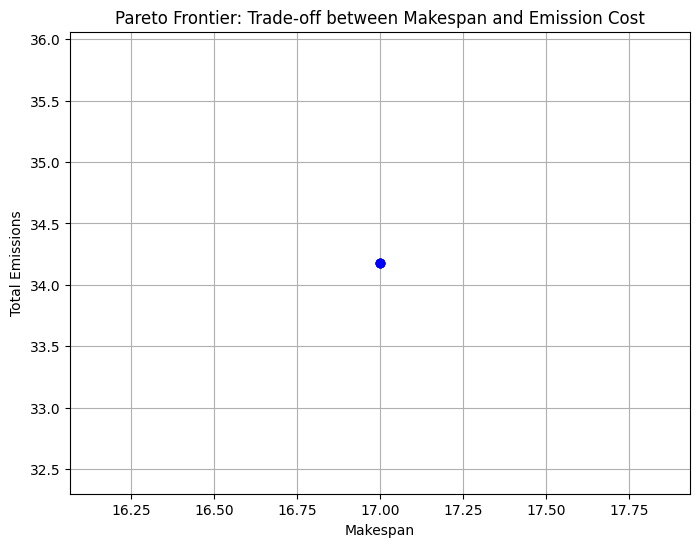

In [108]:
import gurobipy as gp
from gurobipy import GRB

# =========================================================
# 1. DATA
# =========================================================

jobs = [1, 2, 3, 4]
machines = [1, 2, 3, 4]

operations = {
    1: [1,2,3,4],
    2: [1,2,3,4],
    3: [1,2,3,4],
    4: [1,2,3]
}

# Processing times p[j,k,m]
p = {
 (1,1,1):8,(1,1,2):1,(1,1,3):4,(1,1,4):5,
 (1,2,1):2,(1,2,2):1,(1,2,3):10,(1,2,4):4,
 (1,3,1):4,(1,3,2):2,(1,3,3):8,(1,3,4):2,
 (1,4,1):5,(1,4,2):7,(1,4,3):8,(1,4,4):8,

 (2,1,1):3,(2,1,2):2,(2,1,3):5,(2,1,4):7,
 (2,2,1):5,(2,2,2):10,(2,2,3):10,(2,2,4):8,
 (2,3,1):9,(2,3,2):7,(2,3,3):8,(2,3,4):6,
 (2,4,1):7,(2,4,2):1,(2,4,3):6,(2,4,4):8,

 (3,1,1):3,(3,1,2):8,(3,1,3):1,(3,1,4):3,
 (3,2,1):8,(3,2,2):2,(3,2,3):9,(3,2,4):8,
 (3,3,1):2,(3,3,2):8,(3,3,3):5,(3,3,4):6,
 (3,4,1):9,(3,4,2):7,(3,4,3):6,(3,4,4):8,

 (4,1,1):4,(4,1,2):2,(4,1,3):7,(4,1,4):2,
 (4,2,1):5,(4,2,2):1,(4,2,3):1,(4,2,4):6,
 (4,3,1):9,(4,3,2):7,(4,3,3):10,(4,3,4):3
}

# Emission costs e[j,k,m]
e = {
 (1,1,1):3.20,(1,1,2):4.71,(1,1,3):2.75,(1,1,4):3.79,
 (1,2,1):3.84,(1,2,2):2.24,(1,2,3):1.05,(1,2,4):2.63,
 (1,3,1):3.59,(1,3,2):1.62,(1,3,3):4.73,(1,3,4):2.17,
 (1,4,1):1.97,(1,4,2):3.21,(1,4,3):2.53,(1,4,4):4.69,

 (2,1,1):2.36,(2,1,2):4.15,(2,1,3):2.07,(2,1,4):1.01,
 (2,2,1):4.46,(2,2,2):2.79,(2,2,3):2.94,(2,2,4):2.33,
 (2,3,1):4.48,(2,3,2):4.92,(2,3,3):1.96,(2,3,4):2.53,
 (2,4,1):3.82,(2,4,2):4.25,(2,4,3):2.54,(2,4,4):3.65,

 (3,1,1):3.01,(3,1,2):3.36,(3,1,3):4.48,(3,1,4):4.50,
 (3,2,1):1.06,(3,2,2):1.58,(3,2,3):4.48,(3,2,4):4.88,
 (3,3,1):3.49,(3,3,2):2.59,(3,3,3):1.32,(3,3,4):2.31,
 (3,4,1):4.49,(3,4,2):1.14,(3,4,3):1.27,(3,4,4):3.52,

 (4,1,1):4.04,(4,1,2):3.82,(4,1,3):1.40,(4,1,4):1.67,
 (4,2,1):4.18,(4,2,2):2.17,(4,2,3):2.50,(4,2,4):1.58,
 (4,3,1):1.68,(4,3,2):1.32,(4,3,3):4.48,(4,3,4):3.48
}


# =========================================================
# 2. MODEL
# =========================================================

model = gp.Model("Job_Shop_Emission_Cost")

# =========================================================
# 3. VARIABLES
# =========================================================

x = model.addVars(
    [(j,k,m) for j in jobs for k in operations[j] for m in machines],
    vtype=GRB.BINARY,
    name="x"
)

S = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="S"
)

C = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="C"
)

Cmax = model.addVar(lb=0, name="Cmax")

# Variables to track emission cost
total_emission = model.addVar(lb=0, name="TotalEmission")

# Sequencing variables
y = model.addVars(
    [(j,k,jp,kp,m)
     for j in jobs for k in operations[j]
     for jp in jobs for kp in operations[jp]
     if (j,k) < (jp,kp)
     for m in machines],
    vtype=GRB.BINARY,
    name="y"
)

# =========================================================
# 4. OBJECTIVES
# =========================================================

# Primary Objective: Minimize makespan
model.setObjective(Cmax, GRB.MINIMIZE)

# Add second objective: Minimize emission cost
# We'll do a trade-off approach by using a weighted sum for both objectives
alpha = 0.5  # Weight for makespan (can adjust for Pareto front)
beta = 1 - alpha  # Weight for emission cost

# Set the multi-objective function
model.setObjectiveN(Cmax, 0)  # Minimize makespan
model.setObjectiveN(total_emission, 1)  # Minimize emission cost

# =========================================================
# 5. CONSTRAINTS
# =========================================================

# (i) Assignment - Each job-operation must be assigned to exactly one machine
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            gp.quicksum(x[j,k,m] for m in machines) == 1
        )

# Completion time - Define the completion time for each job-operation on each machine
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
        )

# Precedence - Ensure that the operations within each job follow the correct order
for j in jobs:
    for idx in range(len(operations[j]) - 1):
        k = operations[j][idx]
        k_next = operations[j][idx + 1]
        model.addConstr(S[j,k_next] >= C[j,k])

# Makespan - The completion time of the last operation should define the makespan
for j in jobs:
    for k in operations[j]:
        model.addConstr(Cmax >= C[j,k])

# Sequencing constraints - Ensure that jobs don't overlap on the same machine
M = 1000  # Big-M value
for (j,k,jp,kp,m) in y.keys():
    model.addConstr(
        S[j,k] >= C[jp,kp]
        - M * (1 - y[j,k,jp,kp,m])
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )
    model.addConstr(
        S[jp,kp] >= C[j,k]
        - M * y[j,k,jp,kp,m]
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )

# Emission cost constraint - Calculate total emission cost
model.addConstr(
    total_emission == gp.quicksum(
        e[j,k,m] * x[j,k,m] for j in jobs for k in operations[j] for m in machines
    )
)

# =========================================================
# 6. SOLVE
# =========================================================

model.optimize()

# =========================================================
# 7. OUTPUT
# =========================================================

print("\nOptimal Makespan:", Cmax.X)
print("Total Emission Cost:", total_emission.X)

for j in jobs:
    for k in operations[j]:
        for m in machines:
            if x[j,k,m].X > 0.5:
                print(f"Job {j}, Op {k} -> Machine {m}, "
                      f"Start {S[j,k].X:.2f}, "
                      f"Finish {C[j,k].X:.2f}")

# Now generate Pareto frontier by solving for different alpha values
# List to store the Pareto frontier data
cost = []
emissions = []

# Try different weight values for makespan and emission cost
for alpha in [0.1, 0.2, 0.3, 0.4, 0.5]:
    beta = 1 - alpha
    model.setObjectiveN(Cmax, 0)  # Minimize makespan
    model.setObjectiveN(total_emission, 1)  # Minimize emission cost

    model.optimize()
    
    # Capture the results for Pareto frontier
    if model.status == GRB.OPTIMAL:
        cost.append(Cmax.X)
        emissions.append(total_emission.X)

# Plot the Pareto Frontier
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.plot(cost, emissions, marker='o', linestyle='-', color='b')
plt.title("Pareto Frontier: Trade-off between Makespan and Emission Cost")
plt.ylabel("Total Emissions")
plt.xlabel("Makespan")
plt.grid(True)
plt.show()


In [164]:
import gurobipy as gp
from gurobipy import GRB

# =========================================================
# 1. DATA
# =========================================================

jobs = [1, 2, 3, 4]
machines = [1, 2, 3, 4]

operations = {
    1: [1,2,3,4],
    2: [1,2,3,4],
    3: [1,2,3,4],
    4: [1,2,3]
}

# Processing times p[j,k,m]
p = {
 (1,1,1):8,(1,1,2):1,(1,1,3):4,(1,1,4):5,
 (1,2,1):2,(1,2,2):1,(1,2,3):10,(1,2,4):4,
 (1,3,1):4,(1,3,2):2,(1,3,3):8,(1,3,4):2,
 (1,4,1):5,(1,4,2):7,(1,4,3):8,(1,4,4):8,

 (2,1,1):3,(2,1,2):2,(2,1,3):5,(2,1,4):7,
 (2,2,1):5,(2,2,2):10,(2,2,3):10,(2,2,4):8,
 (2,3,1):9,(2,3,2):7,(2,3,3):8,(2,3,4):6,
 (2,4,1):7,(2,4,2):1,(2,4,3):6,(2,4,4):8,

 (3,1,1):3,(3,1,2):8,(3,1,3):1,(3,1,4):3,
 (3,2,1):8,(3,2,2):2,(3,2,3):9,(3,2,4):8,
 (3,3,1):2,(3,3,2):8,(3,3,3):5,(3,3,4):6,
 (3,4,1):9,(3,4,2):7,(3,4,3):6,(3,4,4):8,

 (4,1,1):4,(4,1,2):2,(4,1,3):7,(4,1,4):2,
 (4,2,1):5,(4,2,2):1,(4,2,3):1,(4,2,4):6,
 (4,3,1):9,(4,3,2):7,(4,3,3):10,(4,3,4):3
}

# Emission costs e[j,k,m]
e = {
 (1,1,1):3.20,(1,1,2):4.71,(1,1,3):2.75,(1,1,4):3.79,
 (1,2,1):3.84,(1,2,2):2.24,(1,2,3):1.05,(1,2,4):2.63,
 (1,3,1):3.59,(1,3,2):1.62,(1,3,3):4.73,(1,3,4):2.17,
 (1,4,1):1.97,(1,4,2):3.21,(1,4,3):2.53,(1,4,4):4.69,

 (2,1,1):2.36,(2,1,2):4.15,(2,1,3):2.07,(2,1,4):1.01,
 (2,2,1):4.46,(2,2,2):2.79,(2,2,3):2.94,(2,2,4):2.33,
 (2,3,1):4.48,(2,3,2):4.92,(2,3,3):1.96,(2,3,4):2.53,
 (2,4,1):3.82,(2,4,2):4.25,(2,4,3):2.54,(2,4,4):3.65,

 (3,1,1):3.01,(3,1,2):3.36,(3,1,3):4.48,(3,1,4):4.50,
 (3,2,1):1.06,(3,2,2):1.58,(3,2,3):4.48,(3,2,4):4.88,
 (3,3,1):3.49,(3,3,2):2.59,(3,3,3):1.32,(3,3,4):2.31,
 (3,4,1):4.49,(3,4,2):1.14,(3,4,3):1.27,(3,4,4):3.52,

 (4,1,1):4.04,(4,1,2):3.82,(4,1,3):1.40,(4,1,4):1.67,
 (4,2,1):4.18,(4,2,2):2.17,(4,2,3):2.50,(4,2,4):1.58,
 (4,3,1):1.68,(4,3,2):1.32,(4,3,3):4.48,(4,3,4):3.48
}


# Constraints
# Assignment constraint (one machine per operation)
for j in jobs:
    for k in ops[j]:
        model.addConstr(
            gp.quicksum(x[j,k,m] for m in machines) == 1
        )

# Completion time for each operation
for j in jobs:
    for k in ops[j]:
        model.addConstr(
            C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
        )

# Precedence constraint (operation order within each job)
for j in jobs:
    for idx in range(len(ops[j]) - 1):
        k = ops[j][idx]
        k_next = ops[j][idx + 1]
        model.addConstr(S[j,k_next] >= C[j,k])

# Makespan constraint
for j in jobs:
    for k in ops[j]:
        model.addConstr(Cmax >= C[j,k])

# Total emission cost calculation
model.addConstr(
    E == gp.quicksum(e.get((j, k, m), 0) * x[j, k, m] for j in jobs for k in ops[j] for m in machines)
)

# Now we define a range for the emission cost and iterate over it
# First, solve for the minimum emission cost
model.setObjective(E, GRB.MINIMIZE)
model.optimize()

min_emission_cost = E.X
print(f"Minimum Emission Cost: {min_emission_cost}")

# Solve for the maximum emission cost
model.setObjective(E, GRB.MAXIMIZE)
model.optimize()

max_emission_cost = E.X
print(f"Maximum Emission Cost: {max_emission_cost}")

# Now we will use these values to create the Pareto frontier by solving for different emission cost constraints
pareto_frontier = []

# Loop through emission cost values to create Pareto frontier
increment = 1  # Adjust the increment size as needed
for emission_constraint in range(int(min_emission_cost), int(max_emission_cost) + increment, increment):
    model.setObjective(Cmax, GRB.MINIMIZE)  # Minimize makespan
    model.addConstr(E <= emission_constraint)  # Set emission cost constraint
    model.optimize()
    
    if model.status == GRB.OPTIMAL:
        pareto_frontier.append((Cmax.X, emission_constraint))  # Store (makespan, emission cost)
    else:
        print(f"Infeasible for emission constraint {emission_constraint}")

# Output the Pareto frontier
print("\nPareto Frontier (Makespan vs Emission Cost):")
for makespan, emission_cost in pareto_frontier:
    print(f"Makespan: {makespan}, Emission Cost: {emission_cost}")

Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 125 rows, 92 columns and 537 nonzeros
Model fingerprint: 0x3aa2b422
Variable types: 32 continuous, 60 integer (60 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 5e+01]

MIP start from previous solve produced solution with objective 41.91 (0.01s)
Loaded MIP start from previous solve with objective 41.91



Presolve removed 109 rows and 46 columns
Presolve time: 0.01s
Presolved: 16 rows, 46 columns, 91 nonzeros
Variable types: 0 continuous, 46 integer (45 binary)

Root relaxation: objective 2.606000e+01, 0 iterations, 0.05 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

*    0     0               0      26.0600000   26.06000  0.00%     -    0s

Explored 1 nodes (0 simplex iterations) in 0.20 seconds (0.00 work units)
Thread count was 4 (of 4 available processors)

Solution count 2: 26.06 41.91 

Optimal solution found (tolerance 1.00e-04)
Best objective 2.606000000000e+01, best bound 2.606000000000e+01, gap 0.0000%
Minimum Emission Cost: 26.060000000000002
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 

Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 58 rows, 92 columns and 264 nonzeros
Model fingerprint: 0x943a6f17
Variable types: 32 continuous, 60 integer (60 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 4e+01]

MIP start from previous solve did not produce a new incumbent solution

Found heuristic solution: objective 26.0000000
Presolve removed 58 rows and 92 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.02 seconds (0.00 work units)
Thread count was 1 (of 4 available processors)

Solution count 2: 14 26 

Optimal solution found (tolerance 1.00e-04)
Best objective 1.400000000000e+01, best bound 1.400000000000e+01, g

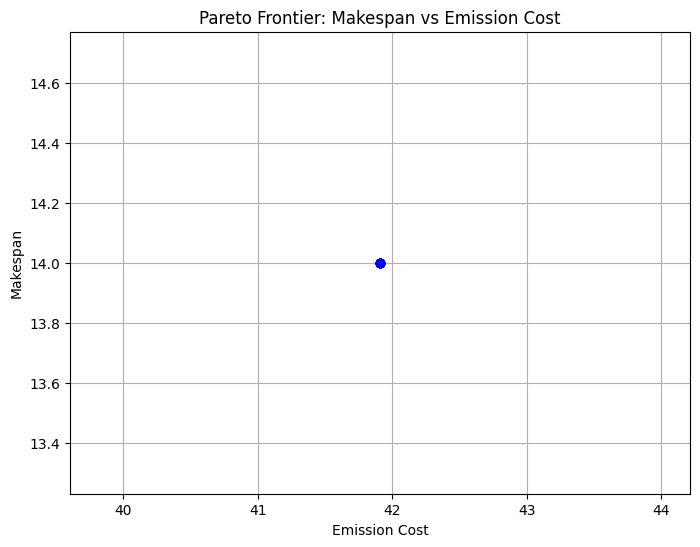

In [163]:
import gurobipy as gp
from gurobipy import GRB
import matplotlib.pyplot as plt

# Assuming the model is already defined and optimized as shown previously

# Pareto frontier list to store (makespan, emission cost) pairs
pareto_frontier = []

# For each emission cost constraint, solve the model again
# Vary the emission cost constraint in small increments
increment = 1  # Adjust the increment size as needed

# You already have the minimum and maximum emission costs from the earlier step
min_emission_cost = E.X
max_emission_cost = E.X + 10  # You can adjust this if you want to set the max emission cost

for emission_constraint in range(int(min_emission_cost), int(max_emission_cost) + increment, increment):
    model.setObjective(Cmax, GRB.MINIMIZE)  # Minimize makespan
    model.addConstr(E <= emission_constraint)  # Set emission cost constraint
    
    # Optimize the model with the emission cost constraint
    model.optimize()
    
    if model.status == GRB.OPTIMAL:
        # Store the (makespan, emission cost) pair in the Pareto frontier
        pareto_frontier.append((Cmax.X, E.X))
        print(f"Emission cost: {emission_constraint}, Makespan: {Cmax.X}, Emission Cost: {E.X}")
    else:
        print(f"Infeasible for emission constraint {emission_constraint}")

# After collecting all feasible points, plot the Pareto frontier
makespans, emission_costs = zip(*pareto_frontier)

plt.figure(figsize=(8, 6))
plt.plot(emission_costs, makespans, marker='o', linestyle='-', color='b')
plt.title('Pareto Frontier: Makespan vs Emission Cost')
plt.xlabel('Emission Cost')
plt.ylabel('Makespan')
plt.grid(True)
plt.show()



### Part 6


In [61]:
import gurobipy as gp
from gurobipy import GRB

# =========================================================
# 1. DATA
# =========================================================

jobs = [1, 2, 3, 4]
machines = [1, 2, 3, 4]

operations = {
    1: [1, 2, 3, 4],
    2: [1, 2, 3, 4],
    3: [1, 2, 3, 4],
    4: [1, 2, 3]
}

p = {
    (1,1,1):8,(1,1,2):1,(1,1,3):4,(1,1,4):5,
    (1,2,1):2,(1,2,2):1,(1,2,3):10,(1,2,4):4,
    (1,3,1):4,(1,3,2):2,(1,3,3):8,(1,3,4):2,
    (1,4,1):5,(1,4,2):7,(1,4,3):8,(1,4,4):8,

    (2,1,1):3,(2,1,2):2,(2,1,3):5,(2,1,4):7,
    (2,2,1):5,(2,2,2):10,(2,2,3):10,(2,2,4):8,
    (2,3,1):9,(2,3,2):7,(2,3,3):8,(2,3,4):6,
    (2,4,1):7,(2,4,2):1,(2,4,3):6,(2,4,4):8,

    (3,1,1):3,(3,1,2):8,(3,1,3):1,(3,1,4):3,
    (3,2,1):8,(3,2,2):2,(3,2,3):9,(3,2,4):8,
    (3,3,1):2,(3,3,2):8,(3,3,3):5,(3,3,4):6,
    (3,4,1):9,(3,4,2):7,(3,4,3):6,(3,4,4):8,

    (4,1,1):4,(4,1,2):2,(4,1,3):7,(4,1,4):2,
    (4,2,1):5,(4,2,2):1,(4,2,3):1,(4,2,4):6,
    (4,3,1):9,(4,3,2):7,(4,3,3):10,(4,3,4):3
}

# =========================================================
# 2. MODEL
# =========================================================

model = gp.Model("JobShop_Makespan_IdleTime")

# =========================================================
# 3. VARIABLES
# =========================================================

x = model.addVars(
    [(j,k,m) for j in jobs for k in operations[j] for m in machines],
    vtype=GRB.BINARY,
    name="x"
)

S = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="S"
)

C = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="C"
)

Cmax = model.addVar(lb=0, name="Cmax")

y = model.addVars(
    [(j,k,jp,kp,m)
     for j in jobs for k in operations[j]
     for jp in jobs for kp in operations[jp]
     if (j,k) < (jp,kp)
     for m in machines],
    vtype=GRB.BINARY,
    name="y"
)

# Idle-time variables
S_start = model.addVars(machines, lb=0, name="S_start")
S_end = model.addVars(machines, lb=0, name="S_end")
Idle = model.addVars(machines, lb=0, name="Idle")

# =========================================================
# 4. CONSTRAINTS
# =========================================================

# Assignment
for j in jobs:
    for k in operations[j]:
        model.addConstr(gp.quicksum(x[j,k,m] for m in machines) == 1)

# Completion time
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
        )

# Job precedence
for j in jobs:
    for idx in range(len(operations[j]) - 1):
        model.addConstr(
            S[j,operations[j][idx+1]] >= C[j,operations[j][idx]]
        )

# Makespan
for j in jobs:
    for k in operations[j]:
        model.addConstr(Cmax >= C[j,k])

# Machine sequencing
M = 1000
for (j,k,jp,kp,m) in y.keys():
    model.addConstr(
        S[j,k] >= C[jp,kp]
        - M * (1 - y[j,k,jp,kp,m])
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )
    model.addConstr(
        S[jp,kp] >= C[j,k]
        - M * y[j,k,jp,kp,m]
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )

# Machine start/end times
for m in machines:
    for j in jobs:
        for k in operations[j]:
            model.addConstr(S_start[m] <= S[j,k] + M * (1 - x[j,k,m]))
            model.addConstr(S_end[m] >= C[j,k] - M * (1 - x[j,k,m]))

# Idle time definition
for m in machines:
    model.addConstr(
        Idle[m] ==
        (S_end[m] - S_start[m]) -
        gp.quicksum(p[j,k,m] * x[j,k,m]
                    for j in jobs for k in operations[j])
    )

# =========================================================
# 5. STEP 1: MINIMIZE MAKESPAN
# =========================================================

model.setObjective(Cmax, GRB.MINIMIZE)
model.optimize()

Cmax_star = Cmax.X
epsilon = 0.01

# =========================================================
# 6. STEP 2: MINIMIZE IDLE TIME (CONSTRAINED)
# =========================================================

model.addConstr(Cmax <= Cmax_star + epsilon)
model.setObjective(gp.quicksum(Idle[m] for m in machines), GRB.MINIMIZE)
model.optimize()

# =========================================================
# 7. OUTPUT
# =========================================================

print("\nOptimal Makespan:", Cmax.X)
print("Total Idle Time:", sum(Idle[m].X for m in machines))

for m in machines:
    print(f"Machine {m} Idle Time: {Idle[m].X:.2f}")

for j in jobs:
    for k in operations[j]:
        for m in machines:
            if x[j,k,m].X > 0.5:
                print(
                    f"Job {j}, Op {k} -> Machine {m}, "
                    f"Start {S[j,k].X:.2f}, "
                    f"Finish {C[j,k].X:.2f}"
                )


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 1020 rows, 523 columns and 4834 nonzeros
Model fingerprint: 0xb7c1f83c
Variable types: 43 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Presolve removed 168 rows and 56 columns
Presolve time: 0.03s
Presolved: 852 rows, 467 columns, 4120 nonzeros
Variable types: 31 continuous, 436 integer (436 binary)
Found heuristic solution: objective 35.0000000

Root relaxation: objective 1.400000e+01, 35 iterations, 0.01 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0   14.000

In [167]:
import gurobipy as gp
from gurobipy import GRB

# =========================================================
# 1. DATA
# =========================================================

jobs = [1, 2, 3, 4]
machines = [1, 2, 3, 4]

operations = {
    1: [1, 2, 3, 4],
    2: [1, 2, 3, 4],
    3: [1, 2, 3, 4],
    4: [1, 2, 3]
}

# Processing times p[j,k,m]
p = {
    (1,1,1):8,(1,1,2):1,(1,1,3):4,(1,1,4):5,
    (1,2,1):2,(1,2,2):1,(1,2,3):10,(1,2,4):4,
    (1,3,1):4,(1,3,2):2,(1,3,3):8,(1,3,4):2,
    (1,4,1):5,(1,4,2):7,(1,4,3):8,(1,4,4):8,

    (2,1,1):3,(2,1,2):2,(2,1,3):5,(2,1,4):7,
    (2,2,1):5,(2,2,2):10,(2,2,3):10,(2,2,4):8,
    (2,3,1):9,(2,3,2):7,(2,3,3):8,(2,3,4):6,
    (2,4,1):7,(2,4,2):1,(2,4,3):6,(2,4,4):8,

    (3,1,1):3,(3,1,2):8,(3,1,3):1,(3,1,4):3,
    (3,2,1):8,(3,2,2):2,(3,2,3):9,(3,2,4):8,
    (3,3,1):2,(3,3,2):8,(3,3,3):5,(3,3,4):6,
    (3,4,1):9,(3,4,2):7,(3,4,3):6,(3,4,4):8,

    (4,1,1):4,(4,1,2):2,(4,1,3):7,(4,1,4):2,
    (4,2,1):5,(4,2,2):1,(4,2,3):1,(4,2,4):6,
    (4,3,1):9,(4,3,2):7,(4,3,3):10,(4,3,4):3
}

# =========================================================
# 2. MODEL
# =========================================================

model = gp.Model("MultiObjective_JobShop")

# =========================================================
# 3. VARIABLES
# =========================================================

# Assignment
x = model.addVars(
    [(j,k,m) for j in jobs for k in operations[j] for m in machines],
    vtype=GRB.BINARY,
    name="x"
)

# Start and completion times
S = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="S"
)

C = model.addVars(
    [(j,k) for j in jobs for k in operations[j]],
    lb=0,
    name="C"
)

# Makespan
Cmax = model.addVar(lb=0, name="Cmax")

# Sequencing variables
y = model.addVars(
    [(j,k,jp,kp,m)
     for j in jobs for k in operations[j]
     for jp in jobs for kp in operations[jp]
     if (j,k) < (jp,kp)
     for m in machines],
    vtype=GRB.BINARY,
    name="y"
)

# Machine finishing times and idle times
F = model.addVars(machines, lb=0, name="F")
I = model.addVars(machines, lb=0, name="I")

# =========================================================
# 4. CONSTRAINTS
# =========================================================

# Assignment constraint
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            gp.quicksum(x[j,k,m] for m in machines) == 1
        )

# Completion time definition
for j in jobs:
    for k in operations[j]:
        model.addConstr(
            C[j,k] == S[j,k] + gp.quicksum(p[j,k,m] * x[j,k,m] for m in machines)
        )

# Job precedence constraints
for j in jobs:
    for idx in range(len(operations[j]) - 1):
        k = operations[j][idx]
        k_next = operations[j][idx + 1]
        model.addConstr(S[j,k_next] >= C[j,k])

# Makespan definition
for j in jobs:
    for k in operations[j]:
        model.addConstr(Cmax >= C[j,k])

# Machine non-overlap constraints
M = 1000
for (j,k,jp,kp,m) in y.keys():
    model.addConstr(
        S[j,k] >= C[jp,kp]
        - M * (1 - y[j,k,jp,kp,m])
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )
    model.addConstr(
        S[jp,kp] >= C[j,k]
        - M * y[j,k,jp,kp,m]
        - M * (2 - x[j,k,m] - x[jp,kp,m])
    )

# Machine finishing times
for j in jobs:
    for k in operations[j]:
        for m in machines:
            model.addConstr(
                F[m] >= C[j,k] - M * (1 - x[j,k,m])
            )

# Idle time definition
for m in machines:
    model.addConstr(
        I[m] == F[m] - gp.quicksum(
            p[j,k,m] * x[j,k,m]
            for j in jobs for k in operations[j]
        )
    )

# =========================================================
# 5. STEP 1: MINIMIZE MAKESPAN
# =========================================================

model.setObjective(Cmax, GRB.MINIMIZE)
model.optimize()

Cmax_star = Cmax.X
print("\nOptimal Makespan:", Cmax_star)

# =========================================================
# 6. STEP 2: FIX MAKESPAN & MINIMIZE IDLE TIME
# =========================================================

model.addConstr(Cmax <= Cmax_star)

model.setObjective(
    gp.quicksum(I[m] for m in machines),
    GRB.MINIMIZE
)

model.optimize()

# =========================================================
# 7. OUTPUT
# =========================================================

print("\nTotal Idle Time:",
      sum(I[m].X for m in machines))

for m in machines:
    print(f"Machine {m} Idle Time: {I[m].X:.2f}")

print("\nSchedule:")
for j in jobs:
    for k in operations[j]:
        for m in machines:
            if x[j,k,m].X > 0.5:
                print(
                    f"Job {j}, Op {k} -> Machine {m}, "
                    f"Start {S[j,k].X:.2f}, "
                    f"Finish {C[j,k].X:.2f}"
                )


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 960 rows, 519 columns and 4650 nonzeros
Model fingerprint: 0x09b836e3
Variable types: 39 continuous, 480 integer (480 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+03]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+03]
Found heuristic solution: objective 30.0000000
Presolve removed 108 rows and 52 columns
Presolve time: 0.09s
Presolved: 852 rows, 467 columns, 4120 nonzeros
Variable types: 31 continuous, 436 integer (436 binary)

Root relaxation: objective 1.400000e+01, 35 iterations, 0.02 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntInf | Incumbent    BestBd   Gap | It/Node Time

     0     0   14.0000

### Question 2, Part 1

In [44]:
import gurobipy as gp
from gurobipy import GRB
import pandas as pd

# Load the dataset
data = pd.read_csv("/Users/MayaBjornvik/Desktop/classificationdata.csv")

# Extract explanatory variables (X) and response variable (y)
#X = data[['var1', 'response']].values   # explanatory variables (var1 to var13)
X = data[['var' + str(i) for i in range(1, 14)]].values   # explanatory variables (var1 to var13)
y = data['response'].values    # binary response variable

# Number of observations and number of explanatory variables
n, p = X.shape

# Create a model
model = gp.Model("SVM")

# Variables: ω (weights), b (bias), ξ (slack variables)
omega = model.addVars(p, lb=-GRB.INFINITY, ub=GRB.INFINITY, name="omega")
b = model.addVar(lb=-GRB.INFINITY, ub=GRB.INFINITY, name="b")
xi = model.addVars(n, lb=0, name="xi")

# Objective function: 1/2 * sum(omega^2) + C/n * sum(xi)
C = 1  # Given value for C
model.setObjective(0.5 * sum(omega[j] * omega[j] for j in range(p)) + C/n * sum(xi[i] for i in range(n)), GRB.MINIMIZE)

# Constraints: y_i * (omega^T * x_i + b) >= 1 - xi_i for all i
for i in range(n):
    model.addConstr(y[i] * (sum(omega[j] * X[i, j] for j in range(p)) + b) >= 1 - xi[i])

# Optimize the model
model.optimize()

# Output the results
if model.status == GRB.OPTIMAL:
    print("Optimal solution found:")
    print("ω (weights):", [omega[j].x for j in range(p)])
    print("b (bias):", b.x)
else:
    print("No optimal solution found.")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 184 rows, 198 columns and 2448 nonzeros
Model fingerprint: 0xfea7531c


Model has 13 quadratic objective terms
Coefficient statistics:
  Matrix range     [1e-02, 7e+02]
  Objective range  [5e-03, 5e-03]
  QObjective range [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve time: 0.07s
Presolved: 184 rows, 198 columns, 2448 nonzeros
Presolved model has 13 quadratic objective terms
Ordering time: 0.00s

Barrier statistics:
 Free vars  : 14
 AA' NZ     : 1.684e+04
 Factor NZ  : 1.702e+04
 Factor Ops : 2.093e+06 (less than 1 second per iteration)
 Threads    : 2

                  Objective                Residual
Iter       Primal          Dual         Primal    Dual     Compl     Time
   0   6.51130935e+05 -6.09491239e-17  1.14e-13 1.06e-08  1.00e+06     0s
   1   6.48367767e+05 -4.51810378e+01  6.49e-08 2.58e-06  2.07e+03     0s
   2   1.64502165e+04 -6.37692706e+01  3.59e-10 2.27e-06  4.49e+01     0s
   3   2.62922171e+02 -1.65532055e+01  1.31e-10 6.94e-07  7.59e-01     0s
   4   2.77281047e+01 -1.84709678e+00  4.30e

### Part 2

In [136]:
import gurobipy as gp
from gurobipy import GRB
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("/Users/MayaBjornvik/Desktop/classificationdata.csv")

# Extract explanatory variables (X) and response variable (y)
X = data[['var' + str(i) for i in range(1, 14)]].values   # explanatory variables (var1 to var13)
y = data['response'].values  # binary response variable

# Number of observations and number of explanatory variables
n, p = X.shape

# Function to solve the SVM for a given C
def solve_svm(C_value):
    # Create a model
    model = gp.Model("SVM")

    # Variables: ω (weights), b (bias), ξ (slack variables)
    omega = model.addVars(p, lb=-GRB.INFINITY, ub=GRB.INFINITY, name="omega")
    b = model.addVar(lb=-GRB.INFINITY, ub=GRB.INFINITY, name="b")
    xi = model.addVars(n, lb=0, name="xi")

    # Objective function: 1/2 * sum(omega^2) + C/n * sum(xi)
    model.setObjective(0.5 * sum(omega[j] * omega[j] for j in range(p)) + C_value/n * sum(xi[i] for i in range(n)), GRB.MINIMIZE)

    # Constraints: y_i * (omega^T * x_i + b) >= 1 - xi_i for all i
    for i in range(n):
        model.addConstr(y[i] * (sum(omega[j] * X[i, j] for j in range(p)) + b) >= 1 - xi[i])

    # Optimize the model
    model.optimize()

    if model.status == GRB.OPTIMAL:
        omega_values = [omega[j].x for j in range(p)]
        b_value = b.x
        objective_value = model.objVal  # Get the objective value
        return omega_values, b_value, objective_value
    else:
        return None, None, None

# Sensitivity analysis: Vary C
C_values = [0.1, 1, 5, 10]
omega_results = []
b_results = []
objective_values = []

for C_value in C_values:
    omega_vals, b_val, obj_val = solve_svm(C_value)
    omega_results.append(omega_vals)
    b_results.append(b_val)
    objective_values.append(obj_val)

# Plotting the results
omega_results_df = pd.DataFrame(omega_results, columns=[f'omega_{i+1}' for i in range(p)])
omega_results_df['C'] = C_values


# Output the results for omega, b, and objective value
for i, C_value in enumerate(C_values):
    print(f"Results for C = {C_value}:")
    print(f"omega: {omega_results_df.iloc[i, :-1].values}")
    print(f"b: {b_results[i]}")
    print(f"Objective Value: {objective_values[i]}")
    print("-" * 50)

for i, C_value in enumerate(C_values):
    omega_avg = sum(omega_results[i]) / len(omega_results[i])  # Calculate the average omega
    print(f"Average omega for C = {C_value}: {abs(omega_avg):.5f}")  # Use absolute value, rounded to 4 decimals


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 184 rows, 198 columns and 2448 nonzeros
Model fingerprint: 0xf9d6ca28
Model has 13 quadratic objective terms
Coefficient statistics:
  Matrix range     [1e-02, 7e+02]
  Objective range  [5e-04, 5e-04]
  QObjective range [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve time: 0.03s
Presolved: 184 rows, 198 columns, 2448 nonzeros
Presolved model has 13 quadratic objective terms
Ordering time: 0.00s

Barrier statistics:
 Free vars  : 14
 AA' NZ     : 1.684e+04
 Factor NZ  : 1.702e+04
 Factor Ops : 2.093e+06 (less than 1 second per iteration)
 Threads    : 2

                  Objective                Residual
Iter       Primal          Dual         Primal    Dual     Compl     Time
   0   3.25565717e+04 -6.094912

### Part 4

In [137]:
import gurobipy as gp
from gurobipy import GRB
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("/Users/MayaBjornvik/Desktop/classificationdata.csv")

# Extract explanatory variables (X) and response variable (y)
X = data[['var' + str(i) for i in range(1, 14)]].values   # explanatory variables (var1 to var13)
y = data['response'].values  # binary response variable

# Number of observations and number of explanatory variables
n, p = X.shape

# Function to solve the SVM for a given C and k
def solve_svm(C_value, k):
    # Create a model
    model = gp.Model("SVM_with_k_features")

    # Variables: ω (weights), b (bias), ξ (slack variables), z (binary variables for feature selection)
    omega = model.addVars(p, lb=-GRB.INFINITY, ub=GRB.INFINITY, name="omega")
    b = model.addVar(lb=-GRB.INFINITY, ub=GRB.INFINITY, name="b")
    xi = model.addVars(n, lb=0, name="xi")
    z = model.addVars(p, vtype=GRB.BINARY, name="z")  # Binary variables for feature selection

    # Objective function: 1/2 * sum(omega^2) + C/n * sum(xi) + lambda * sum(z) (penalty for feature selection)
    lambda_penalty = 0.  # Moderate penalty for feature selection (too large would hurt selection)
    
    model.setObjective(
        0.5 * sum(omega[j] * omega[j] for j in range(p))  # Regular SVM objective (penalizes large weights)
        + C_value / n * sum(xi[i] for i in range(n))      # Slack variables for margin
        + lambda_penalty * sum(z[j] for j in range(p)),   # Penalty to force feature selection
        GRB.MINIMIZE
    )

    # Constraints: 
    # y_i * (omega^T * x_i + b) >= 1 - xi_i for all i
    for i in range(n):
        model.addConstr(y[i] * (sum(omega[j] * X[i, j] for j in range(p)) + b) >= 1 - xi[i])

    # Feature selection constraint: sum(z_j) <= k (no more than k features selected)
    model.addConstr(sum(z[j] for j in range(p)) <= k)

    # Link weights and feature selection: omega[j] = 0 if z[j] = 0 (encourage sparsity)
    for j in range(p):
        model.addConstr(omega[j] <= 10000 * z[j])  # Large constant to enforce sparsity when z[j] = 0
        model.addConstr(omega[j] >= -10000 * z[j])

    # Optimize the model
    model.optimize()

    if model.status == GRB.OPTIMAL:
        omega_values = [omega[j].x for j in range(p)]
        b_value = b.x
        selected_features = [j for j in range(p) if z[j].x > 0.5]  # Get selected features
        
        # Compute predicted values (yhat): sign(w^T * x_i + b)
        yhat = np.sign(np.dot(X, omega_values) + b_value)
        
        # Calculate the objective value: 1/2 * sum(omega^2) + C/n * sum(xi)
        objective_value = model.objVal
        
        return omega_values, b_value, selected_features, yhat, objective_value
    else:
        return None, None, None, None, None

# Sensitivity analysis: Vary C and k
C_values = [1]
k_values = [1, 5, 7, 10, 13]  # Example k values: we can select up to 5, 7, or 10 features
omega_results = []
b_results = []
selected_features_results = []
objective_values = []

for k in k_values:
    for C_value in C_values:
        omega_vals, b_val, selected_features, yhat, objective_value = solve_svm(C_value, k)
        omega_results.append(omega_vals)
        b_results.append(b_val)
        selected_features_results.append(selected_features)
        objective_values.append(objective_value)

# Plotting the results (weights for each C and k combination)
omega_results_df = pd.DataFrame(omega_results, columns=[f'omega_{i+1}' for i in range(p)])
omega_results_df['C'] = [C for k in k_values for C in C_values]
omega_results_df['k'] = [k for k in k_values for _ in C_values]


# Output the results for omega, b, selected features, yhat, and objective value
for idx, (C_value, k_value) in enumerate([(C, k) for k in k_values for C in C_values]):
    print(f"Results for C = {C_value}, k = {k_value}:")
    print(f"omega: {omega_results_df.iloc[idx, :-2].values}")
    print(f"b: {b_results[idx]}")
    print(f"Selected features: {selected_features_results[idx]}")
    print(f"Objective value: {objective_values[idx]}")
    print("-" * 50)

    # Calculate and print the average omega for each C value
for i, C_value in enumerate(C_values):
    omega_avg = sum(omega_results[i]) / p  # Average omega for the i-th C value
    print(f"Average omega for C = {C_value}: {omega_avg}")


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 211 rows, 211 columns and 2513 nonzeros
Model fingerprint: 0x73f0914e
Model has 13 quadratic objective terms
Variable types: 198 continuous, 13 integer (13 binary)
Coefficient statistics:
  Matrix range     [1e-02, 1e+04]
  Objective range  [5e-03, 5e-03]
  QObjective range [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 1.0000000
Presolve time: 0.01s
Presolved: 211 rows, 211 columns, 2513 nonzeros
Presolved model has 13 quadratic objective terms
Variable types: 198 continuous, 13 integer (13 binary)

Root relaxation: objective 5.039293e-01, 335 iterations, 0.01 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  

In [72]:
import gurobipy as gp
from gurobipy import GRB
import pandas as pd

# Load the dataset
data = pd.read_csv("/Users/MayaBjornvik/Desktop/classificationdata.csv")

# Extract explanatory variables (X) and response variable (y)
X = data[['var' + str(i) for i in range(1, 14)]].values   # explanatory variables (var1 to var13)
y = data['response'].values    # binary response variable

# Number of observations and number of explanatory variables
n, p = X.shape

# Function to run the optimization model and print results
def run_model(C, k):
    # Create a model
    model = gp.Model("FSSVM")

    # Variables: omega (weights), b (bias), xi (slack variables), z (binary indicators for weights)
    omega = model.addVars(p, lb=-GRB.INFINITY, ub=GRB.INFINITY, name="omega")
    b = model.addVar(lb=-GRB.INFINITY, ub=GRB.INFINITY, name="b")
    xi = model.addVars(n, lb=0, name="xi")
    z = model.addVars(p, vtype=GRB.BINARY, name="z")  # Binary variables for weight selection

    # Auxiliary variables for absolute values of omega
    abs_omega = model.addVars(p, lb=0, name="abs_omega")

    # Regularization parameter for sparsity
    lambda_sparsity = 0.1  # Adjust to control feature selection

    # Objective function: 1/2 * sum(omega^2) + C/n * sum(xi) + lambda * sum(abs(omega))
    model.setObjective(0.5 * sum(omega[j] * omega[j] for j in range(p)) + 
                       C/n * sum(xi[i] for i in range(n)) + 
                       lambda_sparsity * sum(abs_omega[j] for j in range(p)), GRB.MINIMIZE)

    # Constraints: y_i * (omega^T * x_i + b) >= 1 - xi_i for all i
    for i in range(n):
        model.addConstr(y[i] * (sum(omega[j] * X[i, j] for j in range(p)) + b) >= 1 - xi[i])

    # Constraint: ||omega||_0 <= k, which means sum(z[j]) <= k
    for j in range(p):
        model.addConstr(omega[j] <= z[j] * 1000)  # Big-M constraint
        model.addConstr(omega[j] >= -z[j] * 1000)  # Same for negative values

    # Cardinality constraint: at most k non-zero weights
    model.addConstr(sum(z[j] for j in range(p)) <= k)

    # Link absolute value variables to omega
    for j in range(p):
        model.addConstr(abs_omega[j] >= omega[j])      # abs_omega[j] >= omega[j]
        model.addConstr(abs_omega[j] >= -omega[j])     # abs_omega[j] >= -omega[j]

    # Optimize the model
    model.optimize()

    # Output the results
    if model.status == GRB.OPTIMAL:
        print(f"Optimal solution for C={C}, k={k}:")
        print("ω (weights):", [omega[j].x for j in range(p)])
        print("b (bias):", b.x)
        print("Non-zero weights count:", sum(1 for j in range(p) if z[j].x > 0.5))
        print("Objective value:", model.objVal)
    else:
        print(f"No optimal solution for C={C}, k={k}")

# Sensitivity Analysis for different values of C and k
C_values = [1]  # Different values for regularization parameter C
k_values = [100]  # Different values for the maximum number of non-zero weights (k)

# Loop over all combinations of C and k
for C in C_values:
    for k in k_values:
        print(f"\nAnalyzing for C={C}, k={k}")
        run_model(C, k)



Analyzing for C=1, k=100
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 237 rows, 224 columns and 2565 nonzeros
Model fingerprint: 0xa4a4739b
Model has 13 quadratic objective terms
Variable types: 211 continuous, 13 integer (13 binary)
Coefficient statistics:
  Matrix range     [1e-02, 1e+03]
  Objective range  [5e-03, 1e-01]
  QObjective range [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+02]
Found heuristic solution: objective 2.3000000
Presolve removed 27 rows and 13 columns
Presolve time: 0.00s
Presolved: 210 rows, 211 columns, 2500 nonzeros
Presolved model has 13 quadratic objective terms
Variable types: 211 continuous, 0 integer (0 binary)
Root relaxation presolve time: 0.08s
Root relaxation presolved: 210 rows, 211 columns, 2500 nonzeros
Root relaxation pre


                  Objective                Residual
Iter       Primal          Dual         Primal    Dual     Compl     Time
   0   7.16185534e+06 -3.49722140e+07  2.00e+03 5.33e+02  1.04e+06     0s
   1   8.11454412e+05 -9.86262365e+06  1.76e+02 4.70e+01  1.07e+05     0s
   2   6.35934209e+05 -1.09812372e+06  3.56e-01 9.48e-02  4.04e+03     0s
   3   6.90253735e+03 -1.45367484e+03  4.70e-04 1.25e-04  1.87e+01     0s
   4   3.08447281e+03 -1.65883721e+02  9.81e-05 2.61e-05  7.29e+00     1s
   5   4.06183713e+02 -8.57928089e+01  1.14e-09 1.89e-06  1.10e+00     1s
   6   1.70478421e+01 -2.93180906e+00  1.03e-09 1.33e-07  4.48e-02     1s
   7   2.67657703e+00  7.17808958e-03  1.93e-10 2.01e-09  5.99e-03     1s
   8   7.36572736e-01  3.54256963e-01  7.93e-10 1.88e-10  8.57e-04     1s
   9   6.39344832e-01  4.58399472e-01  7.88e-10 1.22e-10  4.06e-04     1s
  10   5.97229220e-01  5.00230217e-01  3.42e-10 1.99e-12  2.17e-04     1s
  11   5.72726985e-01  5.27344454e-01  5.64e-10 2.73e-11  1

In [151]:
import gurobipy as gp
from gurobipy import GRB
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("/Users/MayaBjornvik/Desktop/classificationdata.csv")

# Extract explanatory variables (X) and response variable (y)
X = data[['var' + str(i) for i in range(1, 14)]].values   # explanatory variables (var1 to var13)
y = data['response'].values  # binary response variable

# Number of observations and number of explanatory variables
n, p = X.shape

# Function to solve the SVM for a given C and k
def solve_svm(C_value, k):
    # Create a model
    model = gp.Model("SVM_with_k_features")

    # Variables: ω (weights), b (bias), ξ (slack variables), z (binary variables for feature selection)
    omega = model.addVars(p, lb=-GRB.INFINITY, ub=GRB.INFINITY, name="omega")
    b = model.addVar(lb=-GRB.INFINITY, ub=GRB.INFINITY, name="b")
    xi = model.addVars(n, lb=0, name="xi")
    z = model.addVars(p, vtype=GRB.BINARY, name="z")  # Binary variables for feature selection

    # Objective function: 1/2 * sum(omega^2) + C/n * sum(xi) (no lambda penalty, just the usual SVM terms)
    model.setObjective(
        0.5 * sum(omega[j] * omega[j] for j in range(p))  # Regular SVM objective (penalizes large weights)
        + C_value / n * sum(xi[i] for i in range(n)),      # Slack variables for margin
        GRB.MINIMIZE
    )

    # Constraints: 
    # y_i * (omega^T * x_i + b) >= 1 - xi_i for all i
    for i in range(n):
        model.addConstr(y[i] * (sum(omega[j] * X[i, j] for j in range(p)) + b) >= 1 - xi[i])

    # Feature selection constraint: sum(z_j) <= k (no more than k features selected)
    model.addConstr(sum(z[j] for j in range(p)) <= k)

    # Link weights and feature selection: omega[j] = 0 if z[j] = 0 (encourage sparsity)
    for j in range(p):
        model.addConstr(omega[j] <= 10000 * z[j])  # Large constant to enforce sparsity when z[j] = 0
        model.addConstr(omega[j] >= -10000 * z[j])

    # Optimize the model
    model.optimize()

    if model.status == GRB.OPTIMAL:
        omega_values = [omega[j].x for j in range(p)]
        b_value = b.x
        selected_features = [j for j in range(p) if z[j].x > 0.5]  # Get selected features
        
        # Compute predicted values (yhat): sign(w^T * x_i + b)
        yhat = np.sign(np.dot(X, omega_values) + b_value)
        
        # Calculate the objective value: 1/2 * sum(omega^2) + C/n * sum(xi)
        objective_value = model.objVal
        
        return omega_values, b_value, selected_features, yhat, objective_value
    else:
        return None, None, None, None, None

# Sensitivity analysis: Vary C and k
C_values = [1]  # You can add more values for C if you like
k_values = [1, 3, 8, 10, 13]  # k values from 0 to 13
#C_values = [0.1, 1, 5, 10]  # You can add more values for C if you like
#k_values = [5]  # k values from 0 to 13


omega_results = []
b_results = []
selected_features_results = []
objective_values = []

for k in k_values:
    for C_value in C_values:
        omega_vals, b_val, selected_features, yhat, objective_value = solve_svm(C_value, k)
        omega_results.append(omega_vals)
        b_results.append(b_val)
        selected_features_results.append(selected_features)
        objective_values.append(objective_value)

# Plotting the results (weights for each C and k combination)
omega_results_df = pd.DataFrame(omega_results, columns=[f'omega_{i+1}' for i in range(p)])
omega_results_df['C'] = [C for k in k_values for C in C_values]
omega_results_df['k'] = [k for k in k_values for _ in C_values]

# Output the results for omega, b, selected features, yhat, and objective value
for idx, (C_value, k_value) in enumerate([(C, k) for k in k_values for C in C_values]):
    print(f"Results for C = {C_value}, k = {k_value}:")
    print(f"omega: {omega_results_df.iloc[idx, :-2].values}")
    print(f"b: {b_results[idx]}")
    print(f"Selected features: {selected_features_results[idx]}")
    print(f"Objective value: {objective_values[idx]}")
    print("-" * 50)


# Calculate and print the average omega for each C_value
for i, C_value in enumerate(C_values):
    # Filter omega results corresponding to the current C_value
    omega_vals_for_C = omega_results[i::len(C_values)]  # Get every nth element where n is len(C_values)
    omega_avg = sum([sum(omega) for omega in omega_vals_for_C]) / sum([len(omega) for omega in omega_vals_for_C])  # Calculate average omega across all k
    print(f"Average omega for C = {C_value}: {abs(omega_avg):.5f}")  # Use absolute value, rounded to 5 decimals

Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 211 rows, 211 columns and 2513 nonzeros
Model fingerprint: 0x73f0914e
Model has 13 quadratic objective terms
Variable types: 198 continuous, 13 integer (13 binary)
Coefficient statistics:
  Matrix range     [1e-02, 1e+04]
  Objective range  [5e-03, 5e-03]
  QObjective range [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 1.0000000
Presolve time: 0.00s
Presolved: 211 rows, 211 columns, 2513 nonzeros
Presolved model has 13 quadratic objective terms
Variable types: 198 continuous, 13 integer (13 binary)

Root relaxation: objective 5.039293e-01, 335 iterations, 0.01 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  

In [172]:
import gurobipy as gp
from gurobipy import GRB
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ===============================
# 1. Load data
# ===============================
data = pd.read_csv("/Users/MayaBjornvik/Desktop/classificationdata.csv")

feature_names = ['var' + str(i) for i in range(1, 14)]
X = data[feature_names].values
y = data['response'].values

n, p = X.shape

# ===============================
# 2. FSSVM Solver
# ===============================
def solve_fssvm(C_value, k_value, M=10):
    model = gp.Model("FSSVM")
    model.setParam('OutputFlag', 0)

    # Variables
    omega = model.addVars(p, lb=-GRB.INFINITY, name="omega")
    b = model.addVar(lb=-GRB.INFINITY, name="b")
    xi = model.addVars(n, lb=0, name="xi")
    z = model.addVars(p, vtype=GRB.BINARY, name="z")

    # Objective
    model.setObjective(
        0.5 * gp.quicksum(omega[j] * omega[j] for j in range(p)) +
        C_value / n * gp.quicksum(xi[i] for i in range(n)),
        GRB.MINIMIZE
    )

    # Margin constraints
    for i in range(n):
        model.addConstr(
            y[i] * (gp.quicksum(omega[j] * X[i, j] for j in range(p)) + b)
            >= 1 - xi[i]
        )

    # Feature selection (Big-M)
    for j in range(p):
        model.addConstr(omega[j] <= M * z[j])
        model.addConstr(omega[j] >= -M * z[j])

    # Cardinality constraint
    model.addConstr(gp.quicksum(z[j] for j in range(p)) <= k_value)

    model.optimize()

    if model.status == GRB.OPTIMAL:
        omega_vals = np.array([omega[j].x for j in range(p)])
        z_vals = np.array([z[j].x for j in range(p)])
        b_val = b.x
        obj_val = model.objVal

        selected_features = [
            feature_names[j] for j in range(p) if z_vals[j] > 0.5
        ]

        return omega_vals, z_vals, selected_features, b_val, obj_val
    else:
        return None, None, None, None, None


# ===============================
# 3. Sensitivity Analysis in C
# ===============================
C_values = [0.1, 1, 5, 10]
k_fixed = 5

print("\n===== Sensitivity Analysis: Varying C =====\n")

for C in C_values:
    omega, z, selected_feats, b_val, obj = solve_fssvm(C, k_fixed)
    norm_omega = np.linalg.norm(omega)

    print(f"C = {C}")
    print(f"Objective value: {obj:.4f}")
    print(f"Bias (b): {b_val:.4f}")
    print(f"||omega||: {norm_omega:.5f}")
    print(f"Selected features: {selected_feats}")
    print("-" * 60)


# ===============================
# 4. Sensitivity Analysis in k
# ===============================
k_values = [1, 3, 8, 10, 13]
C_fixed = 1

print("\n===== Sensitivity Analysis: Varying k =====\n")

for k in k_values:
    omega, z, selected_feats, b_val, obj = solve_fssvm(C_fixed, k)
    norm_omega = np.linalg.norm(omega)

    print(f"k = {k}")
    print(f"Objective value: {obj:.4f}")
    print(f"Bias (b): {b_val:.4f}")
    print(f"||omega||: {norm_omega:.5f}")
    print(f"Selected features: {selected_feats}")
    print("-" * 60)



===== Sensitivity Analysis: Varying C =====



C = 0.1
Objective value: 0.0628
Bias (b): 3.5823
||omega||: 0.10705
Selected features: ['var7', 'var9', 'var10', 'var11', 'var13']
------------------------------------------------------------
C = 1
Objective value: 0.5204
Bias (b): 6.2010
||omega||: 0.25389
Selected features: ['var7', 'var9', 'var10', 'var11', 'var13']
------------------------------------------------------------
C = 5
Objective value: 2.4135
Bias (b): 8.6496
||omega||: 0.37597
Selected features: ['var8', 'var9', 'var10', 'var11', 'var13']
------------------------------------------------------------
C = 10
Objective value: 4.7491
Bias (b): 9.6942
||omega||: 0.41477
Selected features: ['var8', 'var9', 'var10', 'var11', 'var13']
------------------------------------------------------------

===== Sensitivity Analysis: Varying k =====

k = 1
Objective value: 0.5622
Bias (b): 2.3819
||omega||: 0.20534
Selected features: ['var13']
------------------------------------------------------------
k = 3
Objective value: 0.5394
Bias 

### Part 6


In [149]:
import gurobipy as gp
from gurobipy import GRB
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv("/Users/MayaBjornvik/Desktop/classificationdata.csv")

# Extract explanatory variables (X) and response variable (y)
X = data[['var' + str(i) for i in range(1, 14)]].values   # explanatory variables (var1 to var13)
y = data['response'].values  # binary response variable

# Number of observations and number of explanatory variables
n, p = X.shape

# Function to solve the SVM for a given C using the ℓ1-norm (1SVM)
def solve_svm(C_value):
    # Create a model
    model = gp.Model("1SVM")
    
    # Variables: omega (weights), b (bias), xi (slack variables), z (for absolute values of omega)
    omega = model.addVars(p, lb=-GRB.INFINITY, ub=GRB.INFINITY, name="omega")
    b = model.addVar(lb=-GRB.INFINITY, ub=GRB.INFINITY, name="b")
    xi = model.addVars(n, lb=0, name="xi")
    z = model.addVars(p, lb=0, name="z")  # Auxiliary variables for |omega_j|
    
    # Constraints: omega_j = z_j for all j, and -z_j <= omega_j <= z_j
    for j in range(p):
        model.addConstr(omega[j] <= z[j])
        model.addConstr(omega[j] >= -z[j])
    
    # Objective function: sum(z_j) + C/n * sum(xi)
    model.setObjective(sum(z[j] for j in range(p)) + C_value/n * sum(xi[i] for i in range(n)), GRB.MINIMIZE)
    
    # Constraints: y_i * (omega^T * x_i + b) >= 1 - xi_i for all i
    for i in range(n):
        model.addConstr(y[i] * (sum(omega[j] * X[i, j] for j in range(p)) + b) >= 1 - xi[i])
    
    # Optimize the model
    model.optimize()
    

    if model.status == GRB.OPTIMAL:
        omega_values = [omega[j].x for j in range(p)]
        b_value = b.x
        objective_value = model.objVal  # Get the objective value
        return omega_values, b_value, objective_value
    else:
        return None, None, None

# Sensitivity analysis: Vary C
C_values = [0.1, 1, 5, 10]
omega_results = []
b_results = []
objective_values = []

for C_value in C_values:
    omega_vals, b_val, obj_val = solve_svm(C_value)
    omega_results.append(omega_vals)
    b_results.append(b_val)
    objective_values.append(obj_val)

# Plotting the results
omega_results_df = pd.DataFrame(omega_results, columns=[f'omega_{i+1}' for i in range(p)])
omega_results_df['C'] = C_values


# Output the results for omega, b, and objective value
for i, C_value in enumerate(C_values):
    print(f"Results for C = {C_value}:")
    print(f"omega: {omega_results_df.iloc[i, :-1].values}")
    print(f"b: {b_results[i]}")
    print(f"Objective Value: {objective_values[i]}")
    print("-" * 50)

# Calculate and print the average omega for each C_value
for i, C_value in enumerate(C_values):
    # Filter omega results corresponding to the current C_value
    omega_vals_for_C = omega_results[i::len(C_values)]  # Get every nth element where n is len(C_values)
    omega_avg = sum([sum(omega) for omega in omega_vals_for_C]) / sum([len(omega) for omega in omega_vals_for_C])  # Calculate average omega across all k
    print(f"Average omega for C = {C_value}: {abs(omega_avg):.5f}")  # Use absolute value, rounded to 5 decimals


Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4 logical processors, using up to 4 threads

Optimize a model with 210 rows, 211 columns and 2500 nonzeros
Model fingerprint: 0x97429ad1
Coefficient statistics:
  Matrix range     [1e-02, 7e+02]
  Objective range  [5e-04, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve time: 0.03s
Presolved: 210 rows, 211 columns, 2500 nonzeros

Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0      handle free variables                          0s
     212    8.5415161e-02   0.000000e+00   0.000000e+00      0s

Solved in 212 iterations and 0.05 seconds (0.01 work units)
Optimal objective  8.541516059e-02
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (mac64[x86] - Darwin 24.2.0 24C101)

CPU model: Intel(R) Core(TM) i3-1000NG4 CPU @ 1.10GHz
Thread count: 2 physical cores, 4